# Deteksi Marine Heatwave (MHW) di NTT Tahun 2000-2020

Analisis ini dibagi menjadi dua bagian:

**A. Penentuan kejadian MHW regional**
- Data SST harian 2000–2020 dipisahkan berdasarkan grid.
- Setiap grid memiliki klimatologi dan ambang P90 masing-masing (Hobday et al. 2016).
- Klimatologi dan P90 dihitung menggunakan jendela kalender 11 hari (±5 hari), kemudian dihaluskan dengan moving average 31 hari.
- MHW dideteksi secara independen pada setiap grid.
- Kejadian awal adalah SST > P90 selama minimal 5 hari berturut-turut.
- Dua kejadian yang dipisahkan celah maksimal 2 hari digabung jika SST pada seluruh hari celah tidak turun di bawah klimatologi.
- Setiap hari dihitung persentase grid laut yang mengalami MHW.
- Hari dengan persentase minimal 15% memenuhi indikasi MHW regional (MHW terjadi minimal pada 15% dari total grid laut valid).
- Hari-hari tersebut dikelompokkan menjadi kejadian MHW regional dengan aturan yang sama: minimal 5 hari berturut-turut, dan dua periode yang dipisahkan celah maksimal 2 hari digabung menjadi satu kejadian.

**Kategori**

Menurut Hobday et al. (2018), pengkategorian didasarkan pada kelipatan dari selisih antara suhu rata-rata klimatologis lokal (climatological mean) dan ambang batas persentil ke-90 (90th percentile) di lokasi tersebut:

- Category I – Moderate (Sedang): Terjadi ketika anomali suhu berada pada kelipatan 1–2× dari selisih ambang batas lokal tersebut.

- Category II – Strong (Kuat): Terjadi pada kelipatan 2–3× dari selisih ambang batas lokal.

- Category III – Severe (Parah): Terjadi pada kelipatan 3–4× dari selisih ambang batas lokal.

- Category IV – Extreme (Ekstrem): Terjadi ketika anomali suhu melebihi 4× (>4×) dari selisih ambang batas lokal.

**B. Penentuan intensitas maksimum**

- Identifikasi kejadian MHW per grid: setiap grid memiliki nilai klimatologi dan ambang batas P90 masing-masing. MHW pada suatu grid ditentukan ketika SST melampaui P90 selama minimal 5 hari berturut-turut. Jeda hingga 2 hari digabungkan ke dalam satu kejadian apabila SST selama hari jeda tidak turun di bawah klimatologi.

- Identifikasi kejadian MHW regional: hitung persentase grid yang mengalami MHW setiap hari terhadap jumlah grid laut dengan data valid. Hari dengan minimal 15% grid mengalami MHW memenuhi kriteria regional.

- Identifikasi seluruh kejadian regional: kelompokkan hari-hari yang memenuhi ambang 15% menjadi periode kejadian regional (minimal 5 hari berturut-turut, celah maksimal 2 hari digabung).

- Perhitungan intensitas maksimum setiap grid. Untuk setiap kejadian MHW regional:

    - Identifikasi seluruh grid yang mengalami MHW selama periode kejadian regional.

    - Hitung intensitas harian pada setiap hari ketika grid mengalami MHW, yaitu selisih SST aktual terhadap klimatologi (definisi intensitas Hobday et al. 2016).

    - Ambil nilai intensitas tertinggi pada setiap grid selama kejadian regional tersebut.

    Rumus:

    I_max,e(i,j) = max [SST(i,j,t) - Clim(i,j,t)]

    dengan t ∈ T_MHW,e(i,j).

    Keterangan:

    I_max,e(i,j): Intensitas MHW maksimum pada grid (i,j) untuk kejadian regional ke-e.

    e: Identitas kejadian MHW regional.

    i,j: Koordinat setiap grid.

    t: Waktu pengamatan ketika grid mengalami MHW.

    T_MHW,e(i,j): Kumpulan hari ketika grid (i,j) mengalami MHW dalam kejadian regional ke-e.

    SST(i,j,t): Suhu permukaan laut aktual.

    Clim(i,j,t): Klimatologi harian SST pada grid (i,j).

    Selisih terhadap P90 (SST − P90) dapat dipakai sebagai alternatif dengan mengubah parameter `INTENSITY_BASIS` pada bagian pengaturan.

- Penentuan Top 3 kejadian regional berdasarkan intensitas maksimum: tentukan intensitas maksimum regional dari seluruh nilai intensitas maksimum grid pada setiap kejadian regional. Urutkan seluruh kejadian berdasarkan nilai intensitas maksimum regional dari terbesar hingga terkecil, kemudian pilih tiga kejadian dengan nilai tertinggi.

Rumus:

I_max,regional(e) = max [I_max,e(i,j)]

dengan perhitungan dilakukan terhadap seluruh grid yang mengalami MHW pada kejadian regional ke-e.

- Pemetaan distribusi intensitas maksimum: petakan nilai intensitas maksimum dari seluruh grid yang mengalami MHW pada masing-masing dari tiga kejadian regional terpilih.

- Ekspor hasil: simpan intensitas maksimum setiap grid, informasi kejadian regional, serta tiga kejadian regional terpilih ke dalam format CSV.

## 1. Persiapan Pustaka

In [2]:

# Jika pustaka belum tersedia, jalankan:
# %pip install xarray netCDF4 h5netcdf pandas numpy matplotlib scipy tqdm

import os
import glob
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

## 2. Pengaturan direktori dan parameter

In [3]:
DATA_DIR = r"C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP"
FILE_PATTERN = "*.nc"
OUTPUT_DIR = r"C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc"

# Sesuaikan jika nama variabel SST bukan sst
SST_VARIABLE = "sst"

# Baseline klimatologi
BASELINE_START = "2000-01-01"
BASELINE_END   = "2020-12-31"

# Parameter deteksi per grid
PERCENTILE = 90
CLIM_WINDOW = 11       # ±5 hari dari hari kalender
SMOOTH_WINDOW = 31     # penghalusan klimatologi dan threshold
MIN_DURATION = 5       # minimal hari berturut-turut
MAX_GAP = 2            # celah maksimal (hari) yang digabung

# True : segmen SST > P90 yang kurang dari MIN_DURATION hari dibuang lebih dulu, baru celah <= MAX_GAP digabung
# False: celah digabung lebih dulu, baru durasi total diperiksa
FILTER_BEFORE_MERGE = True

# Parameter kejadian regional
REGIONAL_THRESHOLD_PCT = 15   # persentase minimal grid laut yang mengalami MHW
REGIONAL_MIN_DURATION = 5     # minimal hari berturut-turut
REGIONAL_MAX_GAP = 2          # celah maksimal (hari) yang digabung

# Dasar perhitungan intensitas MHW
# Intensitas = SST aktual - klimatologi harian
INTENSITY_BASIS = "climatology"

# Pemilihan kejadian regional
# Berdasarkan rata-rata intensitas maksimum seluruh grid
REGIONAL_RANKING_BASIS = "mean_grid_max_intensity"

os.makedirs(OUTPUT_DIR, exist_ok=True)

os.makedirs(OUTPUT_DIR, exist_ok=True)

## 3. Membaca dan menggabungkan data SST

Hasil akhir disusun sebagai dimensi `(time, lat, lon)`.

In [4]:
files = sorted(
    f for f in glob.glob(os.path.join(DATA_DIR, "*.nc"))
    if os.path.isfile(f)
)

print("Jumlah file ditemukan:", len(files))
print("File:", files)

if not files:
    raise FileNotFoundError("File NetCDF tidak ditemukan!")

sst_file = os.path.join(DATA_DIR, "DATA-SST-2000-2020.nc")

ds = xr.open_dataset(sst_file)

print(ds)

Jumlah file ditemukan: 2
File: ['C:\\Users\\WELCOME\\Downloads\\MENGOLDAT KLIMTROP\\DATA-CHLA-DAILY.nc', 'C:\\Users\\WELCOME\\Downloads\\MENGOLDAT KLIMTROP\\DATA-SST-2000-2020.nc']
<xarray.Dataset> Size: 442MB
Dimensions:       (time: 7671, latitude: 90, longitude: 160)
Coordinates:
  * time          (time) datetime64[ns] 61kB 2000-01-01 ... 2020-12-31
  * latitude      (latitude) float32 360B -11.97 -11.92 -11.87 ... -7.575 -7.525
  * longitude     (longitude) float32 640B 118.0 118.1 118.1 ... 125.9 126.0
Data variables:
    analysed_sst  (time, latitude, longitude) float32 442MB ...
Attributes:
    Conventions:       CF-1.11
    title:             Global Sea and Ice Surface Temperature, L4, 5km daily ...
    institution:       Danish Meteorological Institute, DMI
    source:            ESA SST CCI v3.0 and C3S v3.0 L3U, AASTIv2 IST L2P. OS...
    history:           Version 1.0
    references:        Høyer, J. L. and She, J., Optimal interpolation of sea...
    comment:           IN 

In [5]:
# Normalisasi nama koordinat yang umum digunakan
rename_map = {}
for old, new in [
    ("latitude", "lat"), ("longitude", "lon"),
    ("Latitude", "lat"), ("Longitude", "lon"),
    ("valid_time", "time")
]:
    if old in ds.coords or old in ds.dims:
        if new not in ds.coords and new not in ds.dims:
            rename_map[old] = new

if rename_map:
    ds = ds.rename(rename_map)

if SST_VARIABLE not in ds.data_vars:
    candidates = [v for v in ds.data_vars if "sst" in v.lower()]
    if len(candidates) == 1:
        SST_VARIABLE = candidates[0]
        print("Variabel SST otomatis dipilih:", SST_VARIABLE)
    else:
        raise KeyError(f"Variabel {SST_VARIABLE!r} tidak ditemukan. Variabel tersedia: {list(ds.data_vars)}")

sst = ds[SST_VARIABLE].squeeze()

required = {"time", "lat", "lon"}
if not required.issubset(set(sst.dims)):
    raise ValueError(f"Dimensi SST harus memuat {required}, tetapi ditemukan {sst.dims}")

sst = sst.transpose("time", "lat", "lon").sortby("time")
sst = sst.sel(time=slice(BASELINE_START, BASELINE_END))

# Konversi Kelvin ke Celsius bila data masih dalam Kelvin
sample_mean = float(sst.mean(skipna=True).compute())
if sample_mean > 100:
    sst = sst - 273.15
    print("SST dikonversi dari Kelvin ke Celsius.")
else:
    print("SST diasumsikan sudah dalam Celsius.")

# Pastikan data harian dan urut
time_index = pd.DatetimeIndex(sst.time.values)
if time_index.has_duplicates:
    sst = sst.groupby("time").mean()
    time_index = pd.DatetimeIndex(sst.time.values)

print("Rentang waktu:", time_index.min(), "s.d.", time_index.max())
print("Jumlah hari:", len(time_index))
print("Dimensi:", sst.shape)

Variabel SST otomatis dipilih: analysed_sst
SST dikonversi dari Kelvin ke Celsius.
Rentang waktu: 2000-01-01 00:00:00 s.d. 2020-12-31 00:00:00
Jumlah hari: 7671
Dimensi: (7671, 90, 160)


## 4. Fungsi indeks hari kalender

Hari kalender diseragamkan ke indeks 1–366. Untuk tahun non-kabisat, tanggal setelah 28 Februari digeser satu indeks agar sejajar dengan kalender tahun kabisat.

In [6]:
def calendar_day_index(dates):
    dates = pd.DatetimeIndex(dates)
    doy = dates.dayofyear.to_numpy().astype(int)
    leap = dates.is_leap_year
    # Pada tahun non-kabisat, tambahkan satu indeks setelah 28 Februari
    doy[(~leap) & (dates.month.to_numpy() > 2)] += 1
    return doy

## 5. Menghitung klimatologi harian dan threshold P90 per grid

Setiap grid dihitung menggunakan data historis grid tersebut sendiri. Jendela 11 hari dibuat melingkar agar akhir dan awal tahun tetap terhubung. Hasil klimatologi dan P90 kemudian dihaluskan dengan jendela 31 hari.

In [7]:

def calculate_daily_climatology(values, day_index, percentile=90,
                                 clim_window=11, smooth_window=31):
    """
    Menghitung klimatologi harian dan threshold P90 untuk satu grid.
    Menggunakan jendela kalender 11 hari dan smoothing 31 hari.
    """

    values = np.asarray(values, dtype=float)
    day_index = np.asarray(day_index, dtype=int)

    if values.ndim != 1 or day_index.ndim != 1:
        raise ValueError("values dan day_index harus berupa array 1 dimensi.")

    if len(values) != len(day_index):
        raise ValueError("Panjang values dan day_index harus sama.")

    if clim_window % 2 == 0 or smooth_window % 2 == 0:
        raise ValueError("clim_window dan smooth_window harus ganjil.")

    # 1. Inisialisasi klimatologi dan threshold
    clim = np.full(366, np.nan, dtype=float)
    thresh = np.full(366, np.nan, dtype=float)

    half = clim_window // 2

    # 2. Menghitung mean dan P90 menggunakan jendela 11 hari
    for day in range(1, 367):

        offsets = np.arange(-half, half + 1)

        selected_days = (
            (day - 1 + offsets) % 366
        ) + 1

        sample = values[np.isin(day_index, selected_days)]
        sample = sample[np.isfinite(sample)]

        if sample.size > 0:
            clim[day - 1] = np.mean(sample)
            thresh[day - 1] = np.percentile(sample, percentile)

    # 3. Smoothing 31 hari secara melingkar (menjaga kontinuitas Desember–Januari)
    if smooth_window and smooth_window > 1:
        clim = uniform_filter1d(clim, size=smooth_window, mode="wrap")
        thresh = uniform_filter1d(thresh, size=smooth_window, mode="wrap")

    return clim, thresh


## 6. Fungsi penggabungan jeda dan identifikasi kejadian

Langkah dilakukan per grid:
1. Tandai hari ketika SST > P90.
2. Pertahankan segmen berurutan dengan durasi minimal 5 hari (bila `FILTER_BEFORE_MERGE = True`).
3. Gabungkan dua segmen jika jarak jedanya maksimal 2 hari **dan** seluruh SST pada hari jeda ≥ klimatologi.
4. Seleksi kejadian dengan durasi total minimal 5 hari.

Hari jeda yang digabung tetap berada di dalam rentang tanggal kejadian, tetapi tidak otomatis dianggap sebagai hari dengan SST > P90.

In [8]:
def find_true_segments(condition):
    """Mengembalikan segmen indeks True secara inklusif (start, end)."""
    idx = np.flatnonzero(condition)
    if idx.size == 0:
        return []
    split_points = np.where(np.diff(idx) > 1)[0] + 1
    groups = np.split(idx, split_points)
    return [(int(g[0]), int(g[-1])) for g in groups if g.size]


def detect_events_one_grid(values, clim_series, threshold_series,
                           dates, min_duration=5, max_gap=2,
                           filter_before_merge=True):
    """Deteksi MHW pada satu grid; output daftar event dan label event harian."""
    valid = np.isfinite(values) & np.isfinite(clim_series) & np.isfinite(threshold_series)
    exceed = valid & (values > threshold_series)
    segments = find_true_segments(exceed)

    # Segmen yang lebih pendek dari durasi minimal tidak dapat menjadi kejadian
    if filter_before_merge:
        segments = [(s, e) for s, e in segments if e - s + 1 >= min_duration]

    # Gap merging: gap <= max_gap dan seluruh SST gap tidak di bawah climatology
    merged = []
    for start, end in segments:
        if not merged:
            merged.append([start, end])
            continue

        prev_end = merged[-1][1]
        gap_start, gap_end = prev_end + 1, start - 1
        gap_length = start - prev_end - 1

        can_merge = False
        if gap_length <= max_gap:
            if gap_length == 0:
                can_merge = True
            else:
                gap_ok = (
                    np.all(np.isfinite(values[gap_start:gap_end + 1])) and
                    np.all(np.isfinite(clim_series[gap_start:gap_end + 1])) and
                    np.all(values[gap_start:gap_end + 1] >= clim_series[gap_start:gap_end + 1])
                )
                can_merge = bool(gap_ok)

        if can_merge:
            merged[-1][1] = end
        else:
            merged.append([start, end])

    events = []
    event_labels = np.zeros(len(values), dtype=np.int32)

    for start, end in merged:
        duration = end - start + 1
        if duration < min_duration:
            continue

        sl = slice(start, end + 1)
        intensity = values[sl] - clim_series[sl]
        threshold_anom = threshold_series[sl] - clim_series[sl]

        valid_int = np.isfinite(intensity) & np.isfinite(threshold_anom) & (threshold_anom > 0)
        if not np.any(valid_int):
            continue

        ratio = np.full(duration, np.nan)
        ratio[valid_int] = intensity[valid_int] / threshold_anom[valid_int]

        # Kategori maksimum selama rentang event
        max_ratio = float(np.nanmax(ratio))
        if max_ratio >= 4:
            category = "Extreme"
        elif max_ratio >= 3:
            category = "Severe"
        elif max_ratio >= 2:
            category = "Strong"
        else:
            category = "Moderate"

        event_id = len(events) + 1
        event_labels[start:end + 1] = event_id

        events.append({
            "event_id": event_id,
            "start_index": start,
            "end_index": end,
            "start_date": pd.Timestamp(dates[start]),
            "end_date": pd.Timestamp(dates[end]),
            "duration_days": duration,
            "max_intensity_degC": float(np.nanmax(intensity)),
            "mean_intensity_degC": float(np.nanmean(intensity)),
            "cumulative_intensity_degC_days": float(np.nansum(intensity)),
            "max_intensity_ratio": max_ratio,
            "category": category
        })

    return events, event_labels

## 7. Menjalankan deteksi untuk seluruh grid

Setiap kombinasi lintang–bujur diproses secara terpisah. Grid yang seluruh datanya kosong dilewati. Output utama:
- `mhw_events_per_grid.csv`: satu baris untuk setiap kejadian pada setiap grid.
- `mhw_daily_per_grid.nc`: SST, klimatologi, P90, anomali, status MHW, ID kejadian, dan rasio intensitas harian.
- `mhw_climatology_threshold_per_grid.nc`: klimatologi dan P90 per hari kalender dan grid.

In [9]:
dates = pd.DatetimeIndex(sst.time.values)
day_idx = calendar_day_index(dates)

sst_values = sst.values.astype(np.float32)
nt, nlat, nlon = sst_values.shape

clim_all = np.full((nt, nlat, nlon), np.nan, dtype=np.float32)
thresh_all = np.full((nt, nlat, nlon), np.nan, dtype=np.float32)
event_id_all = np.zeros((nt, nlat, nlon), dtype=np.int32)
mhw_mask_all = np.zeros((nt, nlat, nlon), dtype=np.uint8)
category_all = np.zeros((nt, nlat, nlon), dtype=np.uint8)

# Kode kategori harian: 0 bukan MHW, 1 Moderate, 2 Strong, 3 Severe, 4 Extreme
event_rows = []
latitudes = sst.lat.values
longitudes = sst.lon.values

total_nan_clim = 0
total_nan_p90 = 0
total_grid = 0

for iy in tqdm(range(nlat), desc="Lintang"):
    for ix in range(nlon):
        series = sst_values[:, iy, ix]
        if np.count_nonzero(np.isfinite(series)) < MIN_DURATION:
            continue

        clim_366, p90_366 = calculate_daily_climatology(
            series, day_idx,
            percentile=PERCENTILE,
            clim_window=CLIM_WINDOW,
            smooth_window=SMOOTH_WINDOW
        )

        total_nan_clim += np.isnan(clim_366).sum()
        total_nan_p90 += np.isnan(p90_366).sum()
        total_grid += 1

        clim_series = clim_366[day_idx - 1]
        p90_series = p90_366[day_idx - 1]

        clim_all[:, iy, ix] = clim_series
        thresh_all[:, iy, ix] = p90_series

        events, labels = detect_events_one_grid(
            series, clim_series, p90_series, dates,
            min_duration=MIN_DURATION,
            max_gap=MAX_GAP,
            filter_before_merge=FILTER_BEFORE_MERGE
        )

        event_id_all[:, iy, ix] = labels
        mhw_mask_all[:, iy, ix] = (labels > 0).astype(np.uint8)

        # Kategori harian berdasarkan rasio intensitas / (P90 - klimatologi)
        denom = p90_series - clim_series
        anomaly = series - clim_series
        ratio = np.divide(
            anomaly, denom,
            out=np.full_like(anomaly, np.nan, dtype=float),
            where=np.isfinite(denom) & (denom > 0)
        )

        in_event = labels > 0
        category_all[in_event & (ratio < 2), iy, ix] = 1
        category_all[in_event & (ratio >= 2) & (ratio < 3), iy, ix] = 2
        category_all[in_event & (ratio >= 3) & (ratio < 4), iy, ix] = 3
        category_all[in_event & (ratio >= 4), iy, ix] = 4

        for ev in events:
            ev["lat"] = float(latitudes[iy])
            ev["lon"] = float(longitudes[ix])
            event_rows.append(ev)

events_df = pd.DataFrame(event_rows)
print("Jumlah kejadian MHW per grid:", len(events_df))
print("Jumlah grid yang memiliki kejadian:", events_df[["lat", "lon"]].drop_duplicates().shape[0] if len(events_df) else 0)

Lintang:   0%|          | 0/90 [00:00<?, ?it/s]

Jumlah kejadian MHW per grid: 484482
Jumlah grid yang memiliki kejadian: 12692


In [10]:
print("Jumlah grid yang dihitung:", total_grid)
print("Total NaN klimatologi:", total_nan_clim)
print("Total NaN threshold P90:", total_nan_p90)

Jumlah grid yang dihitung: 12692
Total NaN klimatologi: 0
Total NaN threshold P90: 0


## 8. Menyimpan katalog kejadian per grid

Setiap baris adalah satu kejadian pada satu grid. `event_id` hanya unik di dalam grid; identitas spasial kejadian ditentukan bersama koordinat `lat` dan `lon`.

In [11]:
catalog_path = os.path.join(OUTPUT_DIR, "mhw_events_per_grid.csv")
events_df.to_csv(catalog_path, index=False)
print("Katalog tersimpan:", catalog_path)

if len(events_df):
    display(events_df.head(10))
else:
    print("Tidak ada kejadian yang memenuhi kriteria.")

Katalog tersimpan: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\mhw_events_per_grid.csv


,event_id,start_index,end_index,start_date,end_date,duration_days,max_intensity_degC,mean_intensity_degC,cumulative_intensity_degC_days,max_intensity_ratio,category,lat,lon
0,1,754,764,2002-01-24,2002-02-03,11,1.691779,1.426022,15.686242,1.840504,Moderate,-11.974993,118.025002
1,2,1080,1102,2002-12-16,2003-01-07,23,1.547289,1.250858,28.769741,1.424348,Moderate,-11.974993,118.025002
2,3,1482,1491,2004-01-22,2004-01-31,10,1.223839,1.112653,11.126530,1.327519,Moderate,-11.974993,118.025002
3,4,1882,1889,2005-02-25,2005-03-04,8,1.399783,1.285923,10.287388,1.329909,Moderate,-11.974993,118.025002
4,5,3471,3475,2009-07-03,2009-07-07,5,0.936642,0.844336,4.221682,1.294170,Moderate,-11.974993,118.025002
5,6,3479,3484,2009-07-11,2009-07-16,6,0.839794,0.786881,4.721287,1.150737,Moderate,-11.974993,118.025002
6,7,3724,3761,2010-03-13,2010-04-19,38,1.937006,1.478157,56.169949,1.993908,Moderate,-11.974993,118.025002
7,8,3788,3799,2010-05-16,2010-05-27,12,1.221860,1.031012,12.372138,1.424607,Moderate,-11.974993,118.025002
8,9,3838,3848,2010-07-05,2010-07-15,11,1.245609,1.073472,11.808193,1.711288,Moderate,-11.974993,118.025002
9,10,3889,3897,2010-08-25,2010-09-02,9,0.956127,0.877167,7.894507,1.322040,Moderate,-11.974993,118.025002


## 9. Menyimpan data harian dan klimatologi ke NetCDF

In [12]:
# 9A. Menyimpan data harian
coords = {
    "time": sst.time.values,
    "lat": latitudes,
    "lon": longitudes
}

daily_ds = xr.Dataset(
    data_vars={
        "sst": (("time", "lat", "lon"), sst_values),
        "climatology": (("time", "lat", "lon"), clim_all),
        "threshold_p90": (("time", "lat", "lon"), thresh_all),
        "sst_anomaly": (("time", "lat", "lon"), sst_values - clim_all),
        "mhw_mask": (("time", "lat", "lon"), mhw_mask_all),
        "event_id": (("time", "lat", "lon"), event_id_all),
        "mhw_category": (("time", "lat", "lon"), category_all)
    },
    coords=coords,
    attrs={
        "title": "Daily Marine Heatwave Detection Per Grid",
        "method": "Hobday et al. (2016), with category levels following Hobday et al. (2018)",
        "baseline": f"{BASELINE_START} to {BASELINE_END}",
        "threshold": "Daily 90th percentile using 11-day calendar window, smoothed with 31-day moving average",
        "event_definition": "SST > P90 for at least 5 days; gaps <=2 days merged only when all gap SST >= climatology"
    }
)

# Metadata variabel
daily_ds["sst"].attrs = {
    "long_name": "Sea Surface Temperature",
    "units": "degree_Celsius"
}

daily_ds["climatology"].attrs = {
    "long_name": "Daily SST Climatology",
    "units": "degree_Celsius"
}

daily_ds["threshold_p90"].attrs = {
    "long_name": "Daily 90th Percentile SST Threshold",
    "units": "degree_Celsius"
}

daily_ds["sst_anomaly"].attrs = {
    "long_name": "Sea Surface Temperature Anomaly",
    "units": "degree_Celsius",
    "description": "SST minus daily climatology"
}

daily_ds["mhw_mask"].attrs = {
    "long_name": "Marine Heatwave Mask",
    "description": "1 = within an identified MHW event, including merged gap days; 0 = outside MHW"
}

daily_ds["event_id"].attrs = {
    "long_name": "Marine Heatwave Event Identifier",
    "description": "Event ID is unique within each grid"
}

daily_ds["mhw_category"].attrs = {
    "long_name": "Marine Heatwave Category",
    "description": "0 = No MHW, 1 = Moderate, 2 = Strong, 3 = Severe, 4 = Extreme"
}

# Metadata satuan
daily_ds["sst"].attrs["units"] = "degree_Celsius"
daily_ds["climatology"].attrs["units"] = "degree_Celsius"
daily_ds["threshold_p90"].attrs["units"] = "degree_Celsius"
daily_ds["sst_anomaly"].attrs["units"] = "degree_Celsius"

daily_path = os.path.join(OUTPUT_DIR, "mhw_daily_per_grid.nc")
daily_ds.to_netcdf(daily_path)

print("Data harian tersimpan:", daily_path)



Data harian tersimpan: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\mhw_daily_per_grid.nc


In [13]:

# 9B. Menyimpan klimatologi dan threshold P90 366 hari
# Menggunakan hasil perhitungan yang sudah tersedia di clim_all dan thresh_all

clim_grid = np.full((366, nlat, nlon), np.nan, dtype=np.float32)
p90_grid = np.full((366, nlat, nlon), np.nan, dtype=np.float32)

for calendar_day in range(1, 367):
    idx = np.flatnonzero(day_idx == calendar_day)

    if idx.size > 0:
        # Ambil satu tanggal representatif untuk setiap hari kalender
        clim_grid[calendar_day - 1, :, :] = clim_all[idx[0], :, :]
        p90_grid[calendar_day - 1, :, :] = thresh_all[idx[0], :, :]

clim_ds = xr.Dataset(
    data_vars={
        "climatology": (("calendar_day", "lat", "lon"), clim_grid),
        "threshold_p90": (("calendar_day", "lat", "lon"), p90_grid)
    },
    coords={
        "calendar_day": np.arange(1, 367),
        "lat": latitudes,
        "lon": longitudes
    },
    attrs={
        "title": "Daily SST Climatology and P90 Threshold Per Grid",
        "baseline": f"{BASELINE_START} to {BASELINE_END}",
        "clim_window": "11-day calendar window",
        "smoothing": "31-day moving average with circular boundary"
    }
)

clim_ds["climatology"].attrs = {
    "long_name": "Daily SST Climatology",
    "units": "degree_Celsius"
}

clim_ds["threshold_p90"].attrs = {
    "long_name": "Daily 90th Percentile SST Threshold",
    "units": "degree_Celsius"
}

clim_path = os.path.join(
    OUTPUT_DIR,
    "mhw_climatology_threshold_per_grid.nc"
)

clim_ds.to_netcdf(clim_path)

print("Klimatologi tersimpan:", clim_path)

Klimatologi tersimpan: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\mhw_climatology_threshold_per_grid.nc


## 10. Pemeriksaan hasil katalog

Ringkasan berikut tetap berbasis kejadian per grid, bukan kejadian regional.

In [14]:
if len(events_df):
    print("Jumlah kejadian menurut kategori:")
    display(events_df["category"].value_counts().rename_axis("category").to_frame("jumlah_event"))

    print("\nDurasi kejadian (hari):")
    display(events_df["duration_days"].describe().to_frame("statistik"))

    print("\n10 kejadian dengan intensitas maksimum tertinggi:")
    display(events_df.sort_values("max_intensity_degC", ascending=False).head(10))

Jumlah kejadian menurut kategori:


,jumlah_event
category,
Moderate,372246
Strong,105078
Severe,7134
Extreme,24



Durasi kejadian (hari):


,statistik
count,484482.000000
mean,14.572649
std,19.741581
min,5.000000
25%,6.000000
50%,9.000000
75%,14.000000
max,291.000000



10 kejadian dengan intensitas maksimum tertinggi:


,event_id,start_index,end_index,start_date,end_date,duration_days,max_intensity_degC,mean_intensity_degC,cumulative_intensity_degC_days,max_intensity_ratio,category,lat,lon
256684,28,5962,6173,2016-04-28,2016-11-25,212,3.954944,1.858465,393.994536,3.212061,Severe,-9.674993,118.875008
260701,25,5963,6172,2016-04-29,2016-11-24,210,3.951247,1.897900,398.559021,3.275659,Severe,-9.624993,118.875008
256651,28,5962,6172,2016-04-28,2016-11-24,211,3.932794,1.838912,388.010384,3.183165,Severe,-9.674993,118.825005
260734,27,5963,6172,2016-04-29,2016-11-24,210,3.927412,1.914195,401.980877,3.151710,Severe,-9.624993,118.925003
256717,26,5963,6172,2016-04-29,2016-11-24,210,3.902584,1.879938,394.786924,3.030574,Severe,-9.674993,118.925003
243864,28,5998,6181,2016-06-03,2016-12-03,184,3.894100,1.721622,316.778502,3.087199,Severe,-9.824993,119.175003
252539,29,5998,6173,2016-06-03,2016-11-25,176,3.886075,1.915629,337.150783,3.115491,Severe,-9.724993,118.875008
260670,24,5962,6172,2016-04-28,2016-11-24,211,3.868329,1.865169,393.550623,3.232433,Severe,-9.624993,118.825005
252507,29,5962,6180,2016-04-28,2016-12-02,219,3.862134,1.788229,391.622172,3.132173,Severe,-9.724993,118.825005
260765,25,5963,6172,2016-04-29,2016-11-24,210,3.861852,1.897106,398.392219,3.077731,Severe,-9.624993,118.975006


## 11. Diagnostik MHW Regional

**Alur:**

1. Data SST harian periode 2000–2020 dianalisis berdasarkan masing-masing grid.
2. Setiap grid memiliki nilai klimatologi dan ambang batas P90 yang dihitung menggunakan metode Hobday et al. (2016).
3. Deteksi MHW dilakukan secara independen pada setiap grid berdasarkan SST yang melampaui P90 selama minimal 5 hari, dengan penggabungan celah maksimal 2 hari.
4. Hitung persentase grid laut yang mengalami MHW setiap hari. Hari dengan minimal 15% grid terdampak memenuhi indikasi kejadian MHW regional.
5. Kelompokkan hari-hari tersebut menjadi kejadian MHW regional: minimal 5 hari berturut-turut, dan periode yang dipisahkan celah maksimal 2 hari digabung.
6. Untuk setiap kejadian regional, hitung intensitas maksimum pada masing-masing grid dari selisih SST aktual terhadap klimatologi pada setiap hari ketika grid tersebut mengalami MHW. Ambil nilai tertinggi selama kejadian regional.
7. Tentukan intensitas maksimum regional dengan mengambil nilai tertinggi dari seluruh grid yang mengalami MHW pada setiap kejadian regional.
8. Urutkan seluruh kejadian regional berdasarkan intensitas maksimum regional dari terbesar hingga terkecil. Pilih tiga kejadian tertinggi (*Top 3*).
9. Petakan distribusi intensitas maksimum dari seluruh grid yang mengalami MHW pada masing-masing dari tiga kejadian terpilih.
10. Ekspor intensitas maksimum setiap grid, informasi tiga kejadian terpilih, serta peta distribusinya.

**Rumus:**

Persentase grid terdampak:

`Persentase MHW = (Jumlah Grid MHW / Jumlah Grid SST Valid) × 100%`

Intensitas maksimum setiap grid:

`I_max,e(i,j) = max [SST(i,j,t) - Clim(i,j,t)]`

dengan `t ∈ T_MHW,e(i,j)`.

Intensitas maksimum regional:

`I_max,regional(e) = max [I_max,e(i,j)]`

**Keterangan:**

- `e`: Identitas kejadian MHW regional.
- `i,j`: Koordinat setiap grid.
- `t`: Waktu pengamatan ketika grid mengalami MHW.
- `I_max,e(i,j)`: Intensitas maksimum MHW pada grid (i,j) selama kejadian regional ke-e.
- `I_max,regional(e)`: Intensitas maksimum dari seluruh grid yang mengalami MHW pada kejadian regional ke-e.
- `SST(i,j,t)`: Suhu permukaan laut aktual.
- `Clim(i,j,t)`: Klimatologi harian SST pada grid (i,j).

**Catatan:**

- Perhitungan intensitas maksimum hanya dilakukan pada hari ketika grid terkait mengalami MHW.
- Grid yang tidak mengalami MHW selama kejadian regional tidak dimasukkan dalam pemetaan intensitas maksimum.
- Pemilihan Top 3 didasarkan pada intensitas maksimum regional, bukan durasi kejadian atau mean grid percentage.
- Mean grid percentage tetap dapat digunakan sebagai informasi tambahan untuk menggambarkan luas cakupan MHW regional.
- Hari jeda regional (hari di dalam kejadian dengan cakupan di bawah 15%) dilaporkan terpisah dari hari MHW regional.

In [15]:
# DIAGNOSTIK: Persentase grid yang mengalami MHW setiap hari

# 1. Identifikasi grid laut yang memiliki data SST valid
valid_grid = np.any(np.isfinite(sst_values), axis=0)

total_ocean_grid = np.sum(valid_grid)

# 2. Identifikasi grid yang memiliki data valid setiap hari
daily_valid_grid = (
    np.isfinite(sst_values) &
    np.isfinite(clim_all) &
    np.isfinite(thresh_all)
)

# 3. Hitung jumlah grid yang mengalami MHW setiap hari
active_grid_daily = np.sum(
    (mhw_mask_all == 1) & daily_valid_grid,
    axis=(1, 2)
)

# 4. Hitung jumlah grid yang memiliki data valid setiap hari
available_grid_daily = np.sum(
    daily_valid_grid,
    axis=(1, 2)
)

# 5. Hitung persentase grid yang mengalami MHW
mhw_percentage = np.divide(
    active_grid_daily,
    available_grid_daily,
    out=np.zeros(len(dates), dtype=float),
    where=available_grid_daily > 0
) * 100

# 6. Hari dengan cakupan MHW minimal REGIONAL_THRESHOLD_PCT
regional_condition = mhw_percentage >= REGIONAL_THRESHOLD_PCT


def build_regional_events(percentage, dates, threshold=15, min_duration=5,
                          max_gap=2, filter_before_merge=True):
    """Kelompokkan hari dengan cakupan >= threshold menjadi kejadian regional.
    Kejadian minimal min_duration hari berturut-turut; periode yang dipisahkan
    celah <= max_gap hari digabung menjadi satu kejadian."""
    flag = percentage >= threshold
    runs = find_true_segments(flag)

    if filter_before_merge:
        runs = [(s, e) for s, e in runs if e - s + 1 >= min_duration]

    merged = []
    for s, e in runs:
        if merged and s - merged[-1][1] - 1 <= max_gap:
            merged[-1][1] = e
        else:
            merged.append([s, e])

    rows = []
    for s, e in merged:
        duration = e - s + 1
        if duration < min_duration:
            continue
        seg = percentage[s:e + 1]
        regional_days = int(np.sum(seg >= threshold))
        rows.append({
            "event_id": len(rows) + 1,
            "start_index": int(s),
            "end_index": int(e),
            "start_date": pd.Timestamp(dates[s]),
            "end_date": pd.Timestamp(dates[e]),
            "duration_days": duration,
            "hari_mhw_regional": regional_days,
            "hari_jeda": duration - regional_days,
            "mean_grid_percentage": float(np.mean(seg)),
            "max_grid_percentage": float(np.max(seg))
        })
    return pd.DataFrame(rows)


# 7. Tabel kejadian regional
regional_events_df = build_regional_events(
    mhw_percentage, dates,
    threshold=REGIONAL_THRESHOLD_PCT,
    min_duration=REGIONAL_MIN_DURATION,
    max_gap=REGIONAL_MAX_GAP,
    filter_before_merge=FILTER_BEFORE_MERGE
)

print("=== HASIL DIAGNOSTIK MHW REGIONAL ===")
print("Total grid laut valid:", total_ocean_grid)
print("Jumlah grid pada hari pertama:", available_grid_daily[0])
print(f"Jumlah hari dengan cakupan MHW >= {REGIONAL_THRESHOLD_PCT}%:", int(np.sum(regional_condition)))
print("Jumlah kejadian regional:", len(regional_events_df))
if len(regional_events_df):
    print("Total hari MHW regional:", int(regional_events_df["hari_mhw_regional"].sum()))
    print("Total hari jeda:", int(regional_events_df["hari_jeda"].sum()))

display(regional_events_df)

# Simpan katalog kejadian regional dan deret persentase harian
regional_events_df.to_csv(os.path.join(OUTPUT_DIR, "mhw_regional_events.csv"), index=False)
pd.DataFrame({
    "tanggal": dates,
    "persen_grid_mhw": mhw_percentage,
    "grid_mhw": active_grid_daily,
    "grid_valid": available_grid_daily
}).to_csv(os.path.join(OUTPUT_DIR, "mhw_regional_daily_percentage.csv"), index=False)

=== HASIL DIAGNOSTIK MHW REGIONAL ===
Total grid laut valid: 12692
Jumlah grid pada hari pertama: 12692
Jumlah hari dengan cakupan MHW >= 15%: 949
Jumlah kejadian regional: 33
Total hari MHW regional: 925
Total hari jeda: 4


,event_id,start_index,end_index,start_date,end_date,duration_days,hari_mhw_regional,hari_jeda,mean_grid_percentage,max_grid_percentage
0,1,752,766,2002-01-22,2002-02-05,15,15,0,35.336695,45.233218
1,2,1078,1100,2002-12-14,2003-01-05,23,23,0,51.243508,82.004412
2,3,1481,1493,2004-01-21,2004-02-02,13,13,0,45.060486,61.542704
3,4,1873,1891,2005-02-16,2005-03-06,19,19,0,57.104351,92.152537
4,5,2543,2559,2006-12-18,2007-01-03,17,17,0,21.466973,28.356445
5,6,2903,2913,2007-12-13,2007-12-23,11,11,0,37.652924,43.673180
6,7,3464,3483,2009-06-26,2009-07-15,20,20,0,25.518043,35.518437
7,8,3489,3498,2009-07-21,2009-07-30,10,10,0,31.566341,42.254964
8,9,3534,3545,2009-09-04,2009-09-15,12,12,0,22.875302,29.695871
9,10,3717,3774,2010-03-06,2010-05-02,58,58,0,49.868095,68.665301


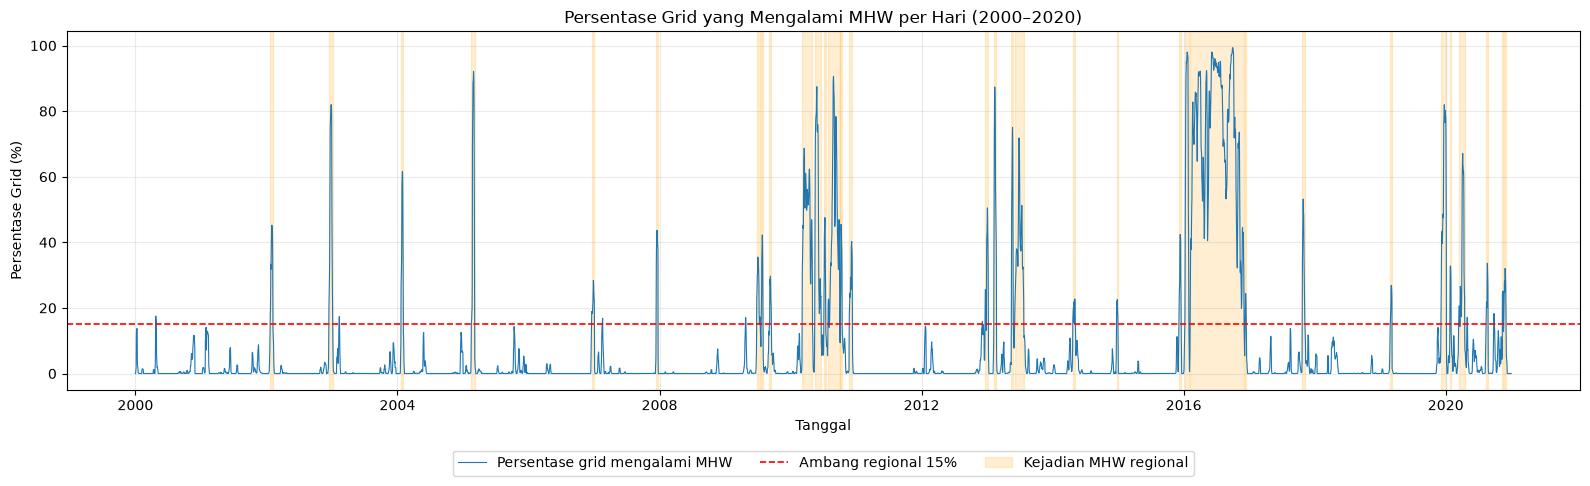

,event_id,start_index,end_index,start_date,end_date,duration_days,hari_mhw_regional,hari_jeda,mean_grid_percentage,max_grid_percentage
23,24,5881,6180,2016-02-07,2016-12-02,300,300,0,73.808226,99.369682
12,13,3862,3926,2010-07-29,2010-10-01,65,64,1,48.406749,90.624015
9,10,3717,3774,2010-03-06,2010-05-02,58,58,0,49.868095,68.665301
18,19,4901,4952,2013-06-02,2013-07-23,52,52,0,39.854754,71.832650
10,11,3787,3823,2010-05-15,2010-06-20,37,37,0,50.578573,87.448787


In [16]:
# PEMERIKSAAN PERSENTASE MHW REGIONAL

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    dates,
    mhw_percentage,
    linewidth=0.8,
    label="Persentase grid mengalami MHW"
)

ax.axhline(
    REGIONAL_THRESHOLD_PCT,
    color="red",
    linestyle="--",
    linewidth=1.2,
    label=f"Ambang regional {REGIONAL_THRESHOLD_PCT}%"
)

for k, (_, ev) in enumerate(regional_events_df.iterrows()):
    ax.axvspan(
        ev["start_date"], ev["end_date"],
        color="orange", alpha=0.18,
        label="Kejadian MHW regional" if k == 0 else None
    )

ax.set_title("Persentase Grid yang Mengalami MHW per Hari (2000–2020)")
ax.set_ylabel("Persentase Grid (%)")
ax.set_xlabel("Tanggal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Lima kejadian regional dengan durasi terpanjang
display(
    regional_events_df
    .sort_values("duration_days", ascending=False)
    .head(5)
)

In [17]:
# DIAGNOSTIK TAMBAHAN: Kejadian regional dengan durasi terpanjang

# 1. Ambil periode kejadian regional terpanjang
focus_event = regional_events_df.sort_values("duration_days", ascending=False).iloc[0]

mask_focus = (
    (dates >= np.datetime64(focus_event["start_date"])) &
    (dates <= np.datetime64(focus_event["end_date"]))
)

# 2. Ambil data MHW dan data valid selama periode tersebut
mhw_focus = mhw_mask_all[mask_focus] == 1

valid_focus = (
    np.isfinite(sst_values[mask_focus]) &
    np.isfinite(clim_all[mask_focus]) &
    np.isfinite(thresh_all[mask_focus])
)

# 3. Hitung jumlah hari valid dan jumlah hari MHW pada setiap grid
valid_days_per_grid = np.sum(valid_focus, axis=0)

active_days_per_grid = np.sum(
    mhw_focus & valid_focus,
    axis=0
)

# 4. Hitung proporsi hari MHW pada setiap grid
grid_mhw_fraction = np.divide(
    active_days_per_grid,
    valid_days_per_grid,
    out=np.full(valid_days_per_grid.shape, np.nan, dtype=float),
    where=valid_days_per_grid > 0
)

# 5. Tampilkan statistik
print("=== DIAGNOSTIK KEJADIAN REGIONAL TERPANJANG ===")
print("Periode:", focus_event["start_date"].date(), "s.d.", focus_event["end_date"].date())
print("Durasi kejadian:", np.sum(mask_focus), "hari")
print("Grid yang pernah mengalami MHW:",
      np.sum(active_days_per_grid > 0))
print("Grid yang mengalami MHW >=50% hari:",
      np.sum(grid_mhw_fraction >= 0.50))
print("Grid yang mengalami MHW >=80% hari:",
      np.sum(grid_mhw_fraction >= 0.80))
print("Grid yang mengalami MHW sepanjang periode:",
      np.sum(grid_mhw_fraction >= 1.00))

print("\nPersentase regional:")
print("Minimum:", mhw_percentage[mask_focus].min())
print("Rata-rata:", mhw_percentage[mask_focus].mean())
print("Maksimum:", mhw_percentage[mask_focus].max())

print("\nKetersediaan grid:")
print("Minimum:", available_grid_daily[mask_focus].min())
print("Maksimum:", available_grid_daily[mask_focus].max())

=== DIAGNOSTIK KEJADIAN REGIONAL TERPANJANG ===
Periode: 2016-02-07 s.d. 2016-12-02
Durasi kejadian: 300 hari
Grid yang pernah mengalami MHW: 12692
Grid yang mengalami MHW >=50% hari: 12086
Grid yang mengalami MHW >=80% hari: 5456
Grid yang mengalami MHW sepanjang periode: 0

Persentase regional:
Minimum: 19.82351087299086
Rata-rata: 73.80822565395525
Maksimum: 99.36968168925307

Ketersediaan grid:
Minimum: 12692
Maksimum: 12692


In [18]:
# DIAGNOSTIK: Persentase MHW regional per bulan pada kejadian terpanjang

df_focus = pd.DataFrame({
    "tanggal": dates[mask_focus],
    "mhw_percentage": mhw_percentage[mask_focus]
})

df_focus["bulan"] = df_focus["tanggal"].dt.to_period("M")

monthly_focus = df_focus.groupby("bulan").agg(
    mean_percentage=("mhw_percentage", "mean"),
    min_percentage=("mhw_percentage", "min"),
    max_percentage=("mhw_percentage", "max"),
    jumlah_hari=("mhw_percentage", "count")
).reset_index()

display(monthly_focus)

,bulan,mean_percentage,min_percentage,max_percentage,jumlah_hari
0,2016-02,59.632223,24.803026,82.792310,23
1,2016-03,83.499131,64.717933,91.979199,31
2,2016-04,63.983612,41.136149,92.207690,30
3,2016-05,74.575298,40.474315,92.333754,31
4,2016-06,94.709266,84.628112,98.046013,30
5,2016-07,91.975133,87.125749,95.201702,31
6,2016-08,68.199679,53.261897,87.866373,31
7,2016-09,88.941065,76.630949,99.369682,30
8,2016-10,67.616888,32.185629,99.290892,31
9,2016-11,44.201597,19.823511,73.566026,30


## 12. Analisis SST Maksimum per Grid untuk Setiap Kejadian Regional

**A. Menghitung intensitas maksimum per grid untuk seluruh kejadian regional dan memilih Top 3**
- Untuk setiap kejadian regional, ambil periode regionalnya.

- Pada setiap grid, hitung intensitas harian (SST − klimatologi) hanya pada hari-hari ketika grid tersebut terdeteksi mengalami MHW.

- Ambil nilai maksimum intensitas tersebut pada setiap grid.

- Intensitas maksimum regional adalah nilai tertinggi dari seluruh grid yang mengalami MHW pada kejadian tersebut.

- Urutkan seluruh kejadian regional berdasarkan intensitas maksimum regional dari terbesar ke terkecil, lalu ambil tiga kejadian teratas.

- Simpan hasil seluruh grid yang mengalami MHW pada tiga kejadian terpilih.

Rumus:
I_max(i,j) = max [SST(i,j,t) - Clim(i,j,t)], untuk t ∈ T_MHW

**Keterangan:**

- I_max(i,j): Intensitas MHW maksimum pada grid (i,j) selama kejadian regional.
- SST(i,j,t): Suhu permukaan laut pada grid (i,j) pada waktu t.
- Clim(i,j,t): Klimatologi harian SST pada grid (i,j).
- t: Waktu pengamatan.
- T_MHW: Kumpulan hari ketika grid tersebut terdeteksi mengalami MHW.

Nilai intensitas dinyatakan dalam °C. Parameter `INTENSITY_BASIS` pada bagian pengaturan mengubah dasar selisih menjadi P90 bila diperlukan.

In [19]:
# ============================================================
# ANALISIS INTENSITAS MAKSIMUM MHW PER GRID
# DAN RATA-RATA INTENSITAS MAKSIMUM REGIONAL
# ============================================================

# 1. Menentukan dasar perhitungan intensitas
reference_all = clim_all
intensity_label = "SST - klimatologi"

# 2. Menyiapkan penyimpanan hasil
regional_intensity_records = []

# Menyimpan array intensitas maksimum setiap grid per kejadian
grid_intensity_by_event = {}

# Menyimpan data jumlah grid yang mengalami MHW
grid_count_by_event = {}

# Menyimpan tanggal kejadian
event_period_by_id = {}


# ============================================================
# 3. PERULANGAN SELURUH KEJADIAN MHW REGIONAL
# ============================================================

for _, ev in regional_events_df.iterrows():

    event_id = int(ev["event_id"])

    start_date = pd.Timestamp(ev["start_date"])
    end_date = pd.Timestamp(ev["end_date"])

    # Periode kejadian regional
    mask = (
        (dates >= np.datetime64(start_date)) &
        (dates <= np.datetime64(end_date))
    )

    if not np.any(mask):
        continue

    # Mengambil data selama periode kejadian
    sst_period = sst_values[mask, :, :]
    clim_period = clim_all[mask, :, :]
    mhw_period = mhw_mask_all[mask, :, :]

    # ========================================================
    # 4. MENGHITUNG INTENSITAS HARIAN
    # ========================================================

    intensity_period = sst_period - clim_period

    # Hanya menggunakan grid dan hari yang terdeteksi MHW
    valid_mhw = (
        (mhw_period == 1) &
        np.isfinite(sst_period) &
        np.isfinite(clim_period) &
        np.isfinite(intensity_period)
    )

    # Mengubah hari non-MHW menjadi NaN
    intensity_mhw_only = np.where(
        valid_mhw,
        intensity_period,
        np.nan
    )

    # ========================================================
    # 5. INTENSITAS MAKSIMUM PADA SETIAP GRID
    # ========================================================

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)

        grid_intensity_max = np.nanmax(
            intensity_mhw_only,
            axis=0
        )

    # Grid tanpa kejadian MHW diberi NaN
    grid_intensity_max[
        ~np.any(valid_mhw, axis=0)
    ] = np.nan

    # Simpan array intensitas maksimum per grid
    grid_intensity_by_event[event_id] = grid_intensity_max

    # ========================================================
    # 6. STATISTIK INTENSITAS SELURUH GRID
    # ========================================================

    valid_values = grid_intensity_max[
        np.isfinite(grid_intensity_max)
    ]

    number_of_grids = len(valid_values)

    grid_count_by_event[event_id] = number_of_grids

    event_period_by_id[event_id] = {
        "start_date": start_date,
        "end_date": end_date
    }

    if number_of_grids == 0:

        mean_regional_intensity = np.nan
        max_regional_intensity = np.nan
        min_regional_intensity = np.nan
        std_regional_intensity = np.nan

        max_latitude = np.nan
        max_longitude = np.nan

    else:

        # Rata-rata intensitas maksimum seluruh grid
        mean_regional_intensity = float(
            np.mean(valid_values)
        )

        # Maksimum intensitas dari seluruh grid
        max_regional_intensity = float(
            np.max(valid_values)
        )

        # Minimum intensitas maksimum grid
        min_regional_intensity = float(
            np.min(valid_values)
        )

        # Simpangan baku intensitas maksimum antargrid
        std_regional_intensity = float(
            np.std(valid_values, ddof=0)
        )

        # Lokasi grid dengan intensitas tertinggi
        iy, ix = np.unravel_index(
            np.nanargmax(grid_intensity_max),
            grid_intensity_max.shape
        )

        max_latitude = float(latitudes[iy])
        max_longitude = float(longitudes[ix])

    # ========================================================
    # 7. MENYIMPAN RINGKASAN SETIAP KEJADIAN REGIONAL
    # ========================================================

    regional_intensity_records.append({

        "event_id": event_id,

        "tanggal_mulai": start_date,
        "tanggal_akhir": end_date,

        "durasi_regional_hari": int(ev["duration_days"]),

        "hari_mhw_regional": int(ev["hari_mhw_regional"]),
        "hari_jeda": int(ev["hari_jeda"]),

        "mean_grid_percentage": float(
            ev["mean_grid_percentage"]
        ),

        "max_grid_percentage": float(
            ev["max_grid_percentage"]
        ),

        "jumlah_grid_mengalami_mhw": number_of_grids,

        "dasar_intensitas": intensity_label,

        "intensitas_maksimum_rata_rata_regional_C":
            mean_regional_intensity,

        "intensitas_maksimum_regional_C":
            max_regional_intensity,

        "intensitas_minimum_maksimum_grid_C":
            min_regional_intensity,

        "standar_deviasi_intensitas_grid_C":
            std_regional_intensity,

        "latitude_grid_maksimum":
            max_latitude,

        "longitude_grid_maksimum":
            max_longitude
    })


# ============================================================
# 8. MEMBUAT DATAFRAME SELURUH KEJADIAN
# ============================================================

regional_intensity_df = pd.DataFrame(
    regional_intensity_records
)


# ============================================================
# 9. PEMERINGKATAN BERDASARKAN RATA-RATA REGIONAL
# ============================================================

regional_intensity_df = (
    regional_intensity_df
    .sort_values(
        "intensitas_maksimum_rata_rata_regional_C",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)

regional_intensity_df["peringkat_regional"] = np.nan

valid_ranking = regional_intensity_df[
    "intensitas_maksimum_rata_rata_regional_C"
].notna()

regional_intensity_df.loc[
    valid_ranking,
    "peringkat_regional"
] = np.arange(1, valid_ranking.sum() + 1)


# ============================================================
# 10. MEMILIH TOP 3 KEJADIAN REGIONAL
# ============================================================

top3_regional_df = (
    regional_intensity_df
    .dropna(
        subset=["intensitas_maksimum_rata_rata_regional_C"]
    )
    .head(3)
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# 11. MENYUSUN DATA INTENSITAS MAKSIMUM SETIAP GRID
#     UNTUK SELURUH KEJADIAN REGIONAL
# ============================================================

all_grid_records = []

for _, ev in regional_intensity_df.dropna(
    subset=["intensitas_maksimum_rata_rata_regional_C"]
).iterrows():

    event_id = int(ev["event_id"])

    grid_max = grid_intensity_by_event[event_id]

    valid_positions = np.where(
        np.isfinite(grid_max)
    )

    for iy, ix in zip(*valid_positions):

        all_grid_records.append({

            "event_id": event_id,

            "peringkat_regional": int(
                ev["peringkat_regional"]
            ),

            "tanggal_mulai": ev["tanggal_mulai"],
            "tanggal_akhir": ev["tanggal_akhir"],

            "durasi_regional_hari":
                ev["durasi_regional_hari"],

            "latitude": float(latitudes[iy]),
            "longitude": float(longitudes[ix]),

            "intensitas_maksimum_C":
                float(grid_max[iy, ix]),

            "intensitas_maksimum_rata_rata_regional_C":
                ev["intensitas_maksimum_rata_rata_regional_C"]
        })


# DataFrame intensitas maksimum seluruh grid
intensity_grid_all_df = pd.DataFrame(
    all_grid_records
)


# ============================================================
# 12. MENGAMBIL DATA GRID TOP 3
# ============================================================

if len(top3_regional_df):

    selected_event_ids = top3_regional_df["event_id"].astype(int)

    intensity_grid_df = intensity_grid_all_df[
        intensity_grid_all_df["event_id"].isin(
            selected_event_ids
        )
    ].copy()

else:

    intensity_grid_df = pd.DataFrame()


# ============================================================
# 13. MENYIMPAN HASIL PERHITUNGAN
# ============================================================

regional_summary_path = os.path.join(
    OUTPUT_DIR,
    "mhw_regional_intensity_mean_all_events.csv"
)

all_grid_path = os.path.join(
    OUTPUT_DIR,
    "mhw_intensity_maximum_per_grid_all_events.csv"
)

top3_summary_path = os.path.join(
    OUTPUT_DIR,
    "mhw_top3_regional_mean_intensity.csv"
)

top3_grid_path = os.path.join(
    OUTPUT_DIR,
    "mhw_intensity_maximum_per_grid_top3.csv"
)

regional_intensity_df.to_csv(
    regional_summary_path,
    index=False
)

intensity_grid_all_df.to_csv(
    all_grid_path,
    index=False
)

top3_regional_df.to_csv(
    top3_summary_path,
    index=False
)

intensity_grid_df.to_csv(
    top3_grid_path,
    index=False
)


# ============================================================
# 14. MENAMPILKAN HASIL
# ============================================================

print("=" * 65)
print("HASIL ANALISIS INTENSITAS MAKSIMUM MHW REGIONAL")
print("=" * 65)

print("Dasar intensitas:", intensity_label)

print(
    "Jumlah kejadian regional:",
    len(regional_intensity_df)
)

print(
    "Jumlah kejadian yang berhasil dihitung:",
    len(regional_intensity_df.dropna(
        subset=["intensitas_maksimum_rata_rata_regional_C"]
    ))
)

print(
    "Jumlah kejadian terpilih:",
    len(top3_regional_df)
)

print(
    "Jumlah grid dari seluruh kejadian:",
    len(intensity_grid_all_df)
)

print(
    "Jumlah grid pada Top 3:",
    len(intensity_grid_df)
)


print("\n=== PERINGKAT KEJADIAN REGIONAL ===")

display(
    regional_intensity_df[
        [
            "peringkat_regional",
            "event_id",
            "tanggal_mulai",
            "tanggal_akhir",
            "durasi_regional_hari",
            "jumlah_grid_mengalami_mhw",
            "intensitas_maksimum_rata_rata_regional_C",
            "intensitas_maksimum_regional_C"
        ]
    ]
)


print("\n=== TOP 3 KEJADIAN MHW REGIONAL ===")

display(
    top3_regional_df[
        [
            "peringkat_regional",
            "event_id",
            "tanggal_mulai",
            "tanggal_akhir",
            "jumlah_grid_mengalami_mhw",
            "intensitas_maksimum_rata_rata_regional_C",
            "intensitas_maksimum_regional_C"
        ]
    ]
)


print("\nLokasi penyimpanan:")
print(regional_summary_path)
print(all_grid_path)
print(top3_summary_path)
print(top3_grid_path)

HASIL ANALISIS INTENSITAS MAKSIMUM MHW REGIONAL
Dasar intensitas: SST - klimatologi
Jumlah kejadian regional: 33
Jumlah kejadian yang berhasil dihitung: 33
Jumlah kejadian terpilih: 3
Jumlah grid dari seluruh kejadian: 262462
Jumlah grid pada Top 3: 37441

=== PERINGKAT KEJADIAN REGIONAL ===


,peringkat_regional,event_id,tanggal_mulai,tanggal_akhir,durasi_regional_hari,jumlah_grid_mengalami_mhw,intensitas_maksimum_rata_rata_regional_C,intensitas_maksimum_regional_C
0,1.0,24,2016-02-07,2016-12-02,300,12692,2.259828,3.954945
1,2.0,23,2016-01-08,2016-01-30,23,12661,2.135705,3.233423
2,3.0,28,2019-12-06,2020-01-04,30,12088,1.972864,3.356878
3,4.0,4,2005-02-16,2005-03-06,19,12232,1.733539,2.979193
4,5.0,10,2010-03-06,2010-05-02,58,12567,1.663762,3.154526
5,6.0,17,2013-02-07,2013-02-21,15,11167,1.630154,2.731730
6,7.0,19,2013-06-02,2013-07-23,52,10163,1.610432,3.054909
7,8.0,13,2010-07-29,2010-10-01,65,12426,1.585570,3.048876
8,9.0,2,2002-12-14,2003-01-05,23,11635,1.568714,2.575397
9,10.0,16,2012-12-20,2013-01-07,19,7364,1.557736,2.765579



=== TOP 3 KEJADIAN MHW REGIONAL ===


,peringkat_regional,event_id,tanggal_mulai,tanggal_akhir,jumlah_grid_mengalami_mhw,intensitas_maksimum_rata_rata_regional_C,intensitas_maksimum_regional_C
0,1.0,24,2016-02-07,2016-12-02,12692,2.259828,3.954945
1,2.0,23,2016-01-08,2016-01-30,12661,2.135705,3.233423
2,3.0,28,2019-12-06,2020-01-04,12088,1.972864,3.356878



Lokasi penyimpanan:
C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\mhw_regional_intensity_mean_all_events.csv
C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\mhw_intensity_maximum_per_grid_all_events.csv
C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\mhw_top3_regional_mean_intensity.csv
C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\mhw_intensity_maximum_per_grid_top3.csv


In [20]:
# ============================================================
# VERIFIKASI HASIL INTENSITAS MAKSIMUM PER GRID
# ============================================================

print("=" * 65)
print("VERIFIKASI PERHITUNGAN INTENSITAS MHW")
print("=" * 65)

for _, ev in top3_regional_df.iterrows():

    event_id = int(ev["event_id"])

    grid_max = grid_intensity_by_event[event_id]

    valid_values = grid_max[
        np.isfinite(grid_max)
    ]

    if len(valid_values) == 0:
        continue

    calculated_mean = np.mean(valid_values)
    calculated_max = np.max(valid_values)

    recorded_mean = ev[
        "intensitas_maksimum_rata_rata_regional_C"
    ]

    recorded_max = ev[
        "intensitas_maksimum_regional_C"
    ]

    print("\n" + "-" * 55)

    print("Peringkat:", int(ev["peringkat_regional"]))
    print("Event ID:", event_id)

    print(
        "Periode:",
        ev["tanggal_mulai"].date(),
        "s.d.",
        ev["tanggal_akhir"].date()
    )

    print("Jumlah grid valid:", len(valid_values))

    print(
        f"Rata-rata hasil hitung ulang: {calculated_mean:.4f} °C"
    )

    print(
        f"Rata-rata dalam tabel:       {recorded_mean:.4f} °C"
    )

    print(
        f"Maksimum hasil hitung ulang: {calculated_max:.4f} °C"
    )

    print(
        f"Maksimum dalam tabel:        {recorded_max:.4f} °C"
    )

    assert np.isclose(
        calculated_mean,
        recorded_mean,
        atol=1e-6
    ), "Rata-rata regional tidak sesuai!"

    assert np.isclose(
        calculated_max,
        recorded_max,
        atol=1e-6
    ), "Maksimum regional tidak sesuai!"

    print("Status: VERIFIKASI BERHASIL")


print("\nSeluruh perhitungan berhasil diverifikasi.")

VERIFIKASI PERHITUNGAN INTENSITAS MHW

-------------------------------------------------------
Peringkat: 1
Event ID: 24
Periode: 2016-02-07 s.d. 2016-12-02
Jumlah grid valid: 12692
Rata-rata hasil hitung ulang: 2.2598 °C
Rata-rata dalam tabel:       2.2598 °C
Maksimum hasil hitung ulang: 3.9549 °C
Maksimum dalam tabel:        3.9549 °C
Status: VERIFIKASI BERHASIL

-------------------------------------------------------
Peringkat: 2
Event ID: 23
Periode: 2016-01-08 s.d. 2016-01-30
Jumlah grid valid: 12661
Rata-rata hasil hitung ulang: 2.1357 °C
Rata-rata dalam tabel:       2.1357 °C
Maksimum hasil hitung ulang: 3.2334 °C
Maksimum dalam tabel:        3.2334 °C
Status: VERIFIKASI BERHASIL

-------------------------------------------------------
Peringkat: 3
Event ID: 28
Periode: 2019-12-06 s.d. 2020-01-04
Jumlah grid valid: 12088
Rata-rata hasil hitung ulang: 1.9729 °C
Rata-rata dalam tabel:       1.9729 °C
Maksimum hasil hitung ulang: 3.3569 °C
Maksimum dalam tabel:        3.3569 °C
Sta

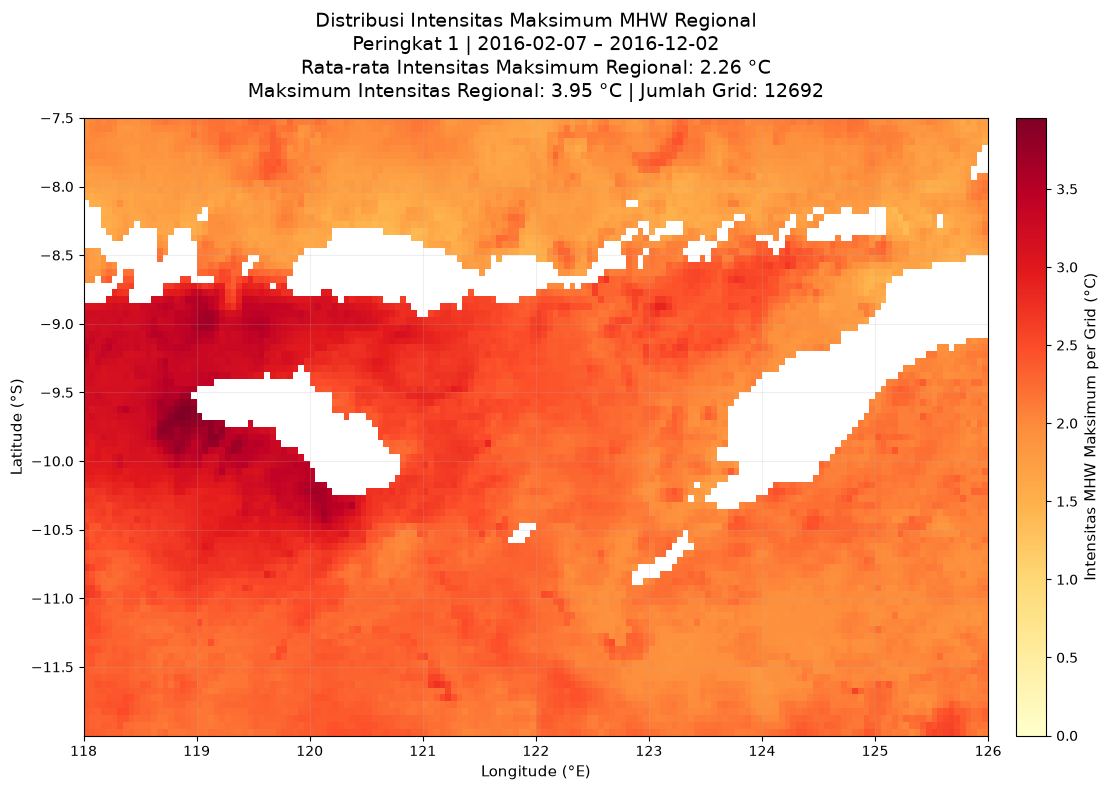

Peta tersimpan: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\PETA_INTENSITAS_MAKSIMUM_MHW_REGIONAL\Intensitas_Maksimum_MHW_Regional_01.png


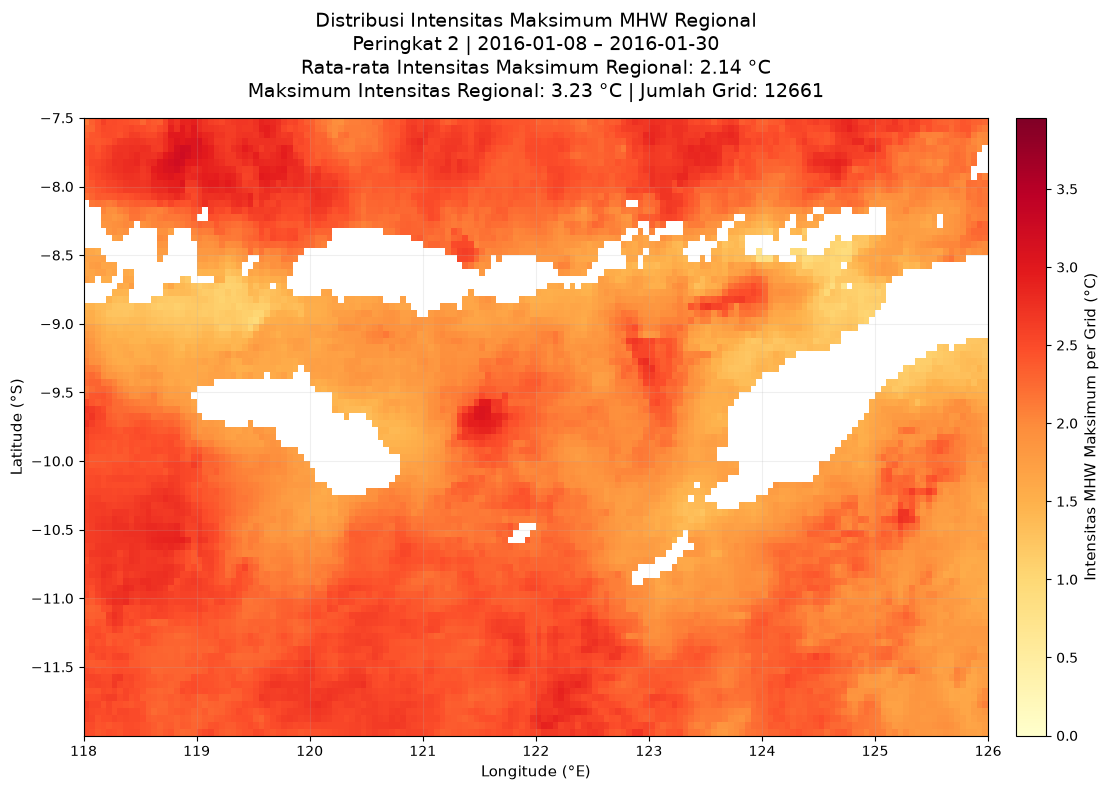

Peta tersimpan: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\PETA_INTENSITAS_MAKSIMUM_MHW_REGIONAL\Intensitas_Maksimum_MHW_Regional_02.png


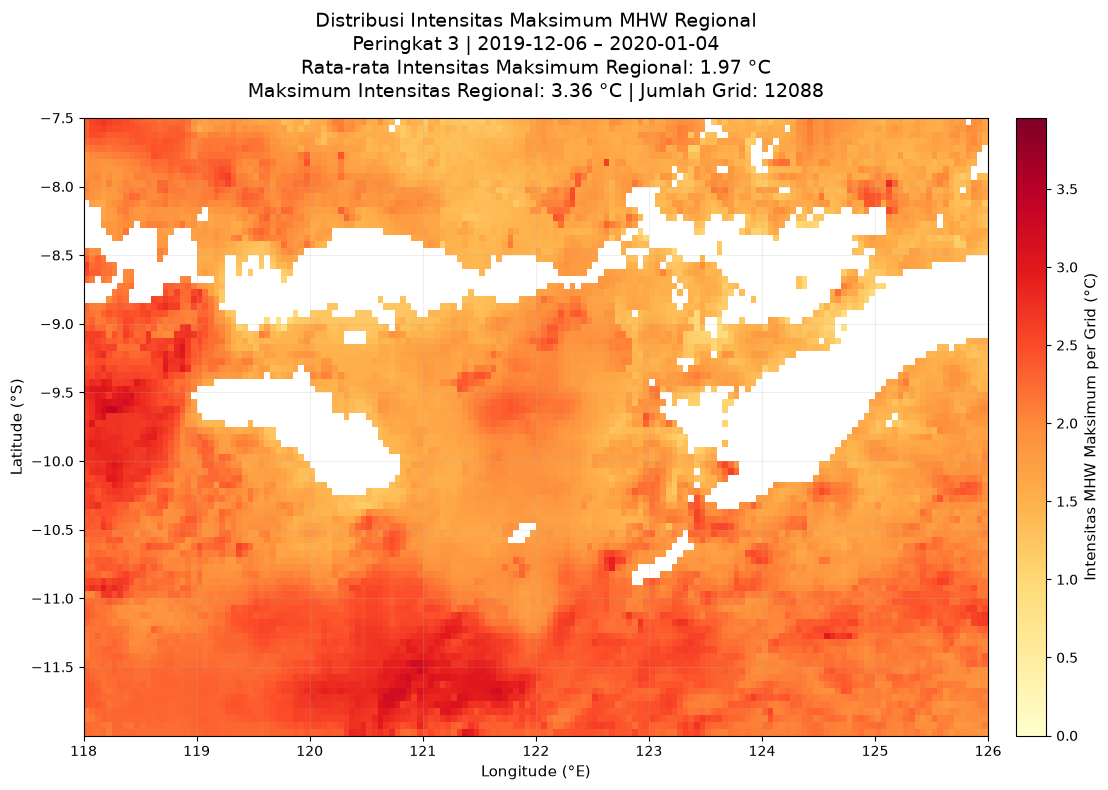

Peta tersimpan: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\PETA_INTENSITAS_MAKSIMUM_MHW_REGIONAL\Intensitas_Maksimum_MHW_Regional_03.png

SELESAI MEMBUAT PETA INTENSITAS MAKSIMUM MHW
Jumlah peta: 3
Folder output: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\PETA_INTENSITAS_MAKSIMUM_MHW_REGIONAL
Skala warna:
Minimum: 0 °C
Maksimum: 3.954944610595703 °C


In [21]:
# ============================================================
# VISUALISASI PETA INTENSITAS MAKSIMUM MHW PER GRID
# ============================================================

# 1. Folder penyimpanan peta
output_map = os.path.join(
    OUTPUT_DIR,
    "PETA_INTENSITAS_MAKSIMUM_MHW_REGIONAL"
)

os.makedirs(output_map, exist_ok=True)


# ============================================================
# 2. MENENTUKAN SKALA WARNA YANG SAMA
# ============================================================

if intensity_grid_df.empty:

    raise ValueError(
        "Tidak ada data intensitas maksimum untuk divisualisasikan."
    )

common_vmin = 0

common_vmax = float(
    intensity_grid_df["intensitas_maksimum_C"].max()
)

if not np.isfinite(common_vmax) or common_vmax <= 0:

    raise ValueError(
        "Rentang nilai intensitas tidak valid."
    )


# ============================================================
# 3. MEMBUAT PETA SETIAP KEJADIAN TOP 3
# ============================================================

for _, ev in top3_regional_df.iterrows():

    event_id = int(ev["event_id"])

    rank = int(ev["peringkat_regional"])

    start_date = pd.Timestamp(
        ev["tanggal_mulai"]
    )

    end_date = pd.Timestamp(
        ev["tanggal_akhir"]
    )

    mean_intensity = float(
        ev["intensitas_maksimum_rata_rata_regional_C"]
    )

    max_intensity = float(
        ev["intensitas_maksimum_regional_C"]
    )

    number_of_grids = int(
        ev["jumlah_grid_mengalami_mhw"]
    )


    # ========================================================
    # 4. MENGAMBIL DATA INTENSITAS GRID
    # ========================================================

    event_grid = intensity_grid_df[
        intensity_grid_df["event_id"] == event_id
    ].copy()

    # Membentuk array spasial berdasarkan koordinat grid
    intensity_map = (
        event_grid
        .pivot(
            index="latitude",
            columns="longitude",
            values="intensitas_maksimum_C"
        )
        .reindex(
            index=latitudes,
            columns=longitudes
        )
        .values
    )


    # ========================================================
    # 5. MEMBUAT PETA
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(12, 8)
    )

    mesh = ax.pcolormesh(
        longitudes,
        latitudes,
        intensity_map,
        shading="auto",
        cmap="YlOrRd",
        vmin=common_vmin,
        vmax=common_vmax
    )

    # Colorbar
    cbar = plt.colorbar(
        mesh,
        ax=ax,
        pad=0.025
    )

    cbar.set_label(
        "Intensitas MHW Maksimum per Grid (°C)",
        fontsize=11
    )


    # ========================================================
    # 6. INFORMASI PETA
    # ========================================================

    ax.set_title(
        f"Distribusi Intensitas Maksimum MHW Regional\n"
        f"Peringkat {rank} | "
        f"{start_date:%Y-%m-%d} – {end_date:%Y-%m-%d}\n"
        f"Rata-rata Intensitas Maksimum Regional: "
        f"{mean_intensity:.2f} °C\n"
        f"Maksimum Intensitas Regional: "
        f"{max_intensity:.2f} °C | "
        f"Jumlah Grid: {number_of_grids}",
        fontsize=14,
        pad=15
    )

    ax.set_xlabel(
        "Longitude (°E)",
        fontsize=11
    )

    ax.set_ylabel(
        "Latitude (°S)",
        fontsize=11
    )

    ax.grid(
        alpha=0.2,
        linestyle="-"
    )

    ax.tick_params(
        labelsize=10
    )

    plt.tight_layout()


    # ========================================================
    # 7. MENYIMPAN PETA
    # ========================================================

    filename = (
        f"Intensitas_Maksimum_MHW_Regional_{rank:02d}.png"
    )

    map_path = os.path.join(
        output_map,
        filename
    )

    plt.savefig(
        map_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print("Peta tersimpan:", map_path)


print("\n" + "=" * 60)
print("SELESAI MEMBUAT PETA INTENSITAS MAKSIMUM MHW")
print("=" * 60)

print("Jumlah peta:", len(top3_regional_df))
print("Folder output:", output_map)

print("Skala warna:")
print("Minimum:", common_vmin, "°C")
print("Maksimum:", common_vmax, "°C")

In [22]:
# SIMPAN HASIL ANALISIS INTENSITAS MAKSIMUM KE CSV

# 1. Buat ringkasan intensitas maksimum setiap kejadian regional
idx_max = intensity_grid_df.groupby("event_id")[
    "intensitas_maksimum_C"
].idxmax()

top3_intensity_regional_df = (
    intensity_grid_df.loc[idx_max]
    .sort_values("intensitas_maksimum_C", ascending=False)
    .reset_index(drop=True)
)

top3_intensity_regional_df["peringkat_regional"] = np.arange(
    1, len(top3_intensity_regional_df) + 1
)

# 2. Pilih kolom ringkasan
top3_intensity_regional_df = top3_intensity_regional_df[
    [
        "peringkat_regional",
        "event_id",
        "tanggal_mulai",
        "tanggal_akhir",
        "durasi_regional_hari",
        "intensitas_maksimum_C",
        "latitude",
        "longitude"
    ]
].rename(columns={
    "intensitas_maksimum_C": "intensitas_maksimum_regional_C",
    "latitude": "latitude_intensitas_maksimum",
    "longitude": "longitude_intensitas_maksimum"
})

# 3. Simpan lokasi CSV
csv_top3 = os.path.join(
    OUTPUT_DIR,
    "Top3_Kejadian_MHW_Regional_Intensitas_Maksimum_NTT_2000-2020.csv"
)

csv_all = os.path.join(
    OUTPUT_DIR,
    "Intensitas_Maksimum_Per_Grid_Top3_MHW_Regional_NTT_2000-2020.csv"
)

# 4. Ekspor ke CSV
top3_intensity_regional_df.to_csv(csv_top3, index=False)
intensity_grid_df.to_csv(csv_all, index=False)

# 5. Tampilkan hasil
print("CSV Top 3 kejadian regional:", csv_top3)
print("CSV intensitas maksimum seluruh grid:", csv_all)

print("\n=== TOP 3 KEJADIAN MHW REGIONAL ===")
display(top3_intensity_regional_df)

print("\n=== INTENSITAS MAKSIMUM PER GRID ===")
display(intensity_grid_df.head())

CSV Top 3 kejadian regional: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\Top3_Kejadian_MHW_Regional_Intensitas_Maksimum_NTT_2000-2020.csv
CSV intensitas maksimum seluruh grid: C:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\MHW-PERGRID-final.nc\Intensitas_Maksimum_Per_Grid_Top3_MHW_Regional_NTT_2000-2020.csv

=== TOP 3 KEJADIAN MHW REGIONAL ===


,peringkat_regional,event_id,tanggal_mulai,tanggal_akhir,durasi_regional_hari,intensitas_maksimum_regional_C,latitude_intensitas_maksimum,longitude_intensitas_maksimum
0,1,24,2016-02-07,2016-12-02,300,3.954945,-9.674993,118.875008
1,2,28,2019-12-06,2020-01-04,30,3.356878,-9.624993,118.225006
2,3,23,2016-01-08,2016-01-30,23,3.233423,-7.774993,118.875008



=== INTENSITAS MAKSIMUM PER GRID ===


,event_id,peringkat_regional,tanggal_mulai,tanggal_akhir,durasi_regional_hari,latitude,longitude,intensitas_maksimum_C,intensitas_maksimum_rata_rata_regional_C
0,24,1,2016-02-07,2016-12-02,300,-11.974993,118.025002,2.380934,2.259828
1,24,1,2016-02-07,2016-12-02,300,-11.974993,118.075005,2.354797,2.259828
2,24,1,2016-02-07,2016-12-02,300,-11.974993,118.125008,2.334757,2.259828
3,24,1,2016-02-07,2016-12-02,300,-11.974993,118.175003,2.331327,2.259828
4,24,1,2016-02-07,2016-12-02,300,-11.974993,118.225006,2.285837,2.259828


## 13. Perhitungan Anomali SST 21 Tahun

**Deskripsi:**

Perhitungan anomali Sea Surface Temperature (SST) dilakukan untuk mengetahui penyimpangan suhu permukaan laut aktual terhadap nilai rata-rata SST selama periode 21 tahun (2000–2020). Perhitungan dilakukan pada setiap grid secara independen dengan membandingkan SST aktual terhadap rata-rata SST pada tanggal kalender yang sama selama periode pengamatan.

Sebagai contoh, SST aktual pada tanggal 15 Januari 2016 dibandingkan dengan rata-rata SST seluruh tanggal 15 Januari selama periode 2000–2020 pada koordinat grid yang sama. Nilai anomali positif menunjukkan bahwa SST aktual lebih tinggi daripada rata-rata 21 tahun, sedangkan nilai anomali negatif menunjukkan bahwa SST aktual lebih rendah daripada rata-rata tersebut.

**Rumus**

    A(i,j,t)=SST(i,j,t) - {SST}_{21}(i,j,d)

**Dengan:**

    (A(i,j,t)): anomali SST pada grid ((i,j)) dan waktu (t).

    (SST(i,j,t)): SST aktual pada grid ((i,j)) dan waktu (t).

    {SST}_{21}(i,j,d): rata-rata SST selama 21 tahun pada grid yang sama untuk tanggal kalender (d).

    (i,j): koordinat lintang dan bujur setiap grid.

    (t): tanggal pengamatan.

    (d): tanggal dan bulan yang sama dengan tanggal pengamatan.

**Tahapan Perhitungan:**

1. Identifikasi data SST: Menggunakan data SST harian periode 2000–2020 yang telah disiapkan pada setiap grid.

2. Pengelompokan berdasarkan tanggal kalender: Data SST dikelompokkan berdasarkan tanggal dan bulan yang sama untuk seluruh tahun pengamatan. Sebagai contoh, seluruh data tanggal 15 Januari dari tahun 2000 hingga 2020 dikelompokkan menjadi satu kelompok.

3. Perhitungan rata-rata SST 21 tahun: Menghitung rata-rata SST pada setiap grid untuk masing-masing tanggal kalender berdasarkan seluruh data yang tersedia selama periode 2000–2020.

4. Perhitungan anomali SST: Mengurangi SST aktual pada setiap tanggal pengamatan dengan rata-rata SST 21 tahun pada tanggal kalender yang sama dan grid yang bersesuaian.

5. Interpretasi hasil: Nilai anomali digunakan untuk mengetahui besarnya penyimpangan SST aktual terhadap kondisi rata-rata selama periode pengamatan. Anomali positif menunjukkan suhu lebih tinggi dari rata-rata, sedangkan anomali negatif menunjukkan suhu lebih rendah dari rata-rata.

**Keterangan:**

- Perhitungan rata-rata dilakukan secara temporal pada setiap grid, tanpa melakukan perataan antargrid.

- Nilai rata-rata dihitung berdasarkan data SST valid yang tersedia pada setiap tanggal kalender.

- Tanggal 29 Februari hanya menggunakan data dari tahun kabisat yang tersedia selama periode pengamatan.

- Hasil perhitungan berupa data anomali SST harian untuk setiap grid dengan satuan °C.

- Anomali positif: SST aktual lebih tinggi daripada rata-rata 21 tahun.

- Anomali negatif: SST aktual lebih rendah daripada rata-rata 21 tahun.

- Anomali nol: SST aktual sama dengan rata-rata 21 tahun.

In [23]:
# PERHITUNGAN ANOMALI SST AKTUAL TERHADAP RATA-RATA 21 TAHUN

# 1. Konversi tanggal
dates_pd = pd.DatetimeIndex(pd.to_datetime(dates))

# 2. Identifikasi tanggal kalender (bulan-tanggal)
calendar_day = dates_pd.strftime("%m-%d")

unique_calendar_days = sorted(set(calendar_day))

# 3. Siapkan array klimatologi rata-rata 21 tahun
sst_mean_21yr = np.full(
    (len(unique_calendar_days), *sst_values.shape[1:]),
    np.nan,
    dtype=np.float32
)

# 4. Hitung rata-rata SST untuk setiap tanggal kalender
for i, day in enumerate(unique_calendar_days):

    # Ambil seluruh data pada tanggal kalender yang sama
    day_indices = np.where(calendar_day == day)[0]

    # Rata-rata SST pada setiap grid selama 21 tahun
    sst_mean_21yr[i, :, :] = np.nanmean(
        sst_values[day_indices, :, :],
        axis=0
    )

# 5. Siapkan array anomali SST
sst_anomaly_all = np.full(
    sst_values.shape,
    np.nan,
    dtype=np.float32
)

# 6. Hitung anomali SST setiap tanggal dan setiap grid
for i, day in enumerate(unique_calendar_days):

    day_indices = np.where(calendar_day == day)[0]

    sst_anomaly_all[day_indices, :, :] = (
        sst_values[day_indices, :, :]
        - sst_mean_21yr[i, :, :]
    )

print("=== HASIL PERHITUNGAN ANOMALI SST ===")
print("Periode data:", dates_pd.min(), "-", dates_pd.max())
print("Jumlah tanggal kalender:", len(unique_calendar_days))
print("Dimensi SST aktual:", sst_values.shape)
print("Dimensi rata-rata SST 21 tahun:", sst_mean_21yr.shape)
print("Dimensi anomali SST:", sst_anomaly_all.shape)
print("Jumlah nilai anomali valid:",
      np.sum(np.isfinite(sst_anomaly_all)))

=== HASIL PERHITUNGAN ANOMALI SST ===
Periode data: 2000-01-01 00:00:00 - 2020-12-31 00:00:00
Jumlah tanggal kalender: 366
Dimensi SST aktual: (7671, 90, 160)
Dimensi rata-rata SST 21 tahun: (366, 90, 160)
Dimensi anomali SST: (7671, 90, 160)
Jumlah nilai anomali valid: 97360332


In [ ]:

# NGGA USAH DI RUNNING, LAMA BGTTT (gua udah ada excelnya)
# EKSPOR HASIL ANOMALI SST KE CSV

# 1. Siapkan indeks tanggal dan koordinat grid
dates_pd = pd.DatetimeIndex(pd.to_datetime(dates))

# 2. Ubah array 3D menjadi tabel
sst_actual_flat = sst_values.reshape(len(dates), -1)
sst_mean_flat = np.empty_like(sst_actual_flat)
sst_anomaly_flat = sst_anomaly_all.reshape(len(dates), -1)

# 3. Ambil rata-rata 21 tahun untuk setiap tanggal pengamatan
calendar_day = dates_pd.strftime("%m-%d")

for i, day in enumerate(unique_calendar_days):
    day_indices = np.where(calendar_day == day)[0]
    sst_mean_flat[day_indices, :] = sst_mean_21yr[i].reshape(1, -1)

# 4. Buat tabel seluruh kombinasi tanggal dan grid
n_time, n_lat, n_lon = sst_values.shape

lat_grid, lon_grid = np.meshgrid(
    latitudes,
    longitudes,
    indexing="ij"
)

anomaly_df = pd.DataFrame({
    "tanggal": np.repeat(dates_pd, n_lat * n_lon),
    "latitude": np.tile(lat_grid.ravel(), n_time),
    "longitude": np.tile(lon_grid.ravel(), n_time),
    "SST_aktual_C": sst_actual_flat.ravel(),
    "rata_rata_SST_21_tahun_C": sst_mean_flat.ravel(),
    "anomali_SST_C": sst_anomaly_flat.ravel()
})

# 5. Ekspor CSV
csv_anomaly = os.path.join(
    DATA_DIR,
    "Anomali_SST_2000-2020_Seluruh_Grid.csv"
)

anomaly_df.to_csv(csv_anomaly, index=False)

print("CSV berhasil disimpan:", csv_anomaly)
print("Jumlah baris:", len(anomaly_df))

display(anomaly_df.head())


: 

## 14. PEMETAAN KOMPOSIT ANOMALI SEA SURFACE TEMPERATURE (SST)


1. Tujuan Pemetaan

        Pemetaan komposit anomali Sea Surface Temperature (SST) dilakukan untuk mengetahui distribusi spasial penyimpangan suhu permukaan laut selama berlangsungnya kejadian Marine Heatwave (MHW) terpilih (Top 3).

        Dalam tahapan ini, hasil pemeringkatan kejadian MHW menjadi dasar utama dalam menentukan kejadian yang akan dipetakan. Tiga kejadian dengan peringkat tertinggi dipilih sebagai periode analisis, kemudian dilakukan perhitungan rata-rata anomali SST pada setiap grid selama masing-masing periode kejadian.

        Dengan demikian, hasil pemeringkatan menentukan kejadian mana yang dipetakan, sedangkan perhitungan anomali menentukan bagaimana kondisi suhu permukaan laut selama masing-masing kejadian tersebut.

        Pemetaan menghasilkan tiga peta komposit anomali SST yang merepresentasikan kondisi rata-rata anomali suhu permukaan laut selama masing-masing kejadian MHW terpilih.

2. Dasar Pemilihan Periode Pemetaan

        Periode pemetaan ditentukan berdasarkan hasil pemeringkatan kejadian MHW yang telah diperoleh pada tahap analisis sebelumnya. Tiga kejadian dengan peringkat tertinggi digunakan sebagai periode komposit anomali SST.

        Kejadian MHW terpilih meliputi:

        | Peringkat | ID Kejadian | Periode Kejadian | Durasi  |
        |-----------|-------------|------------------|---------|
        |     1     |      24     | 7/2/16 – 2/12/16 | 300 hari|
        |     2     |      23     | 8/1/16 – 30/1/16 | 23 hari |
        |     3     |      28     | 6/12/19 – 4// 20 | 30 hari |

        Tanggal awal dan akhir setiap kejadian digunakan untuk menentukan rentang waktu perhitungan komposit anomali SST.

        Pemilihan ketiga kejadian tersebut tidak didasarkan pada nilai anomali SST tertinggi pada setiap grid, melainkan mengacu pada hasil pemeringkatan kejadian MHW secara regional.

3. Metode Perhitungan Anomali SST

      3.1. Perhitungan Rata-rata SST Klimatologis 21 Tahun

      Perhitungan anomali SST diawali dengan menentukan rata-rata SST klimatologis berdasarkan periode data 2000–2020 (21 tahun).

      Rata-rata dihitung pada setiap grid berdasarkan hari dan bulan yang sama selama seluruh periode pengamatan. Sebagai contoh, rata-rata SST tanggal 15 Januari diperoleh dari seluruh data SST tanggal 15 Januari pada tahun 2000–2020.

      Persamaan yang digunakan:

         {SST}_{d}(i,j)= frac{1}{N_d} \sum_{y=2000}^{2020} SST_{y,d}(i,j)
      
      Keterangan:

      - {SST}_{d}(i,j) = rata-rata SST klimatologis pada hari kalender ke-d di grid (i,j).
      - SST_{y,d}(i,j)= SST pada tahun ke-y, hari kalender ke-d, dan grid (i,j).
      - N_d = jumlah data valid pada hari kalender tersebut.
      - i,j = indeks grid spasial (lintang dan bujur).

      Perhitungan dilakukan untuk seluruh hari kalender dalam satu tahun, termasuk 29 Februari.

      3.2. Perhitungan Anomali SST Harian

      Setelah rata-rata SST klimatologis diperoleh, anomali SST harian dihitung dengan mengurangi nilai SST aktual dengan rata-rata SST klimatologis pada hari kalender yang sama.

      Persamaan yang digunakan:

         A(t,i,j)= SST(t,i,j)-\{SST}_{d(t)}(i,j)

      Keterangan:

      - A(t,i,j) = anomali SST pada waktu ke-t dan grid (i,j).
      - SST(t,i,j) = SST aktual pada waktu ke-t dan grid (i,j).
      - {SST}_{d(t)}(i,j) = rata-rata SST klimatologis 21 tahun pada hari dan bulan yang sama dengan waktu ke-t.

      Nilai anomali SST positif menunjukkan bahwa suhu permukaan laut lebih tinggi dibandingkan rata-rata klimatologisnya, sedangkan nilai negatif menunjukkan suhu permukaan laut lebih rendah dibandingkan rata-rata klimatologisnya.

      3.3. Perhitungan Komposit Rata-rata Anomali SST

      Anomali SST harian yang telah diperoleh kemudian dirata-ratakan berdasarkan periode masing-masing kejadian MHW terpilih.

      Perhitungan dilakukan pada setiap grid spasial dengan menggunakan seluruh data anomali SST yang valid selama periode kejadian.

      Persamaan yang digunakan:

         {A}_{e}(i,j)= frac{1}{N_e}\sum_{t=t_0}^{t_1} A(t,i,j)

      Keterangan:

      - {A}_{e}(i,j) = rata-rata anomali SST komposit pada kejadian ke-e di grid (i,j).
      - A(t,i,j) = anomali SST harian pada waktu ke-t dan grid (i,j).
      - t_0 = tanggal awal kejadian MHW.
      - t_1 = tanggal akhir kejadian MHW.
      - N_e = jumlah data anomali SST valid pada grid tersebut selama periode kejadian.

      Perhitungan menggunakan rata-rata dari data yang tersedia dan valid pada setiap grid. Nilai yang tidak tersedia (NaN) tidak diperhitungkan sebagai nol.

      Hasil perhitungan ini berupa satu nilai rata-rata anomali SST untuk setiap grid selama satu kejadian MHW. Nilai tersebut kemudian digunakan sebagai dasar pembuatan peta komposit anomali SST.


5. Tahapan Alur Pemetaan

   Tahapan pemetaan komposit anomali SST dilakukan sebagai berikut:

   1. Menggunakan hasil deteksi MHW per grid. 
      Data hasil deteksi MHW digunakan untuk mengidentifikasi kejadian MHW pada setiap grid spasial.

   2. Mengidentifikasi kejadian MHW secara regional.
      Menghitung persentase grid yang mengalami MHW pada setiap hari untuk mengidentifikasi periode kejadian MHW regional.

   3. Melakukan pemeringkatan kejadian MHW.
      Kejadian MHW regional dianalisis dan diperingkatkan berdasarkan kriteria intensitas yang telah ditetapkan pada tahap analisis sebelumnya.

   4. Memilih tiga kejadian MHW dengan peringkat tertinggi.  
      Tiga kejadian terpilih digunakan sebagai dasar penentuan periode pemetaan komposit anomali SST.

   5. Menghitung rata-rata SST klimatologis 21 tahun. 
      Menghitung rata-rata SST pada setiap grid berdasarkan hari dan bulan yang sama selama periode 2000–2020.

   6. Menghitung anomali SST harian.  
      Mengurangi SST aktual dengan rata-rata SST klimatologis 21 tahun pada hari kalender yang sama.

   7. Menentukan periode komposit.
   Menggunakan tanggal awal dan akhir dari masing-masing kejadian MHW terpilih sebagai rentang waktu perhitungan.

   8. Menghitung rata-rata anomali SST setiap kejadian.  
      Menghitung rata-rata anomali SST pada setiap grid selama periode kejadian MHW berdasarkan data yang valid.

   9. Membuat peta komposit anomali SST.
      Memvisualisasikan hasil perhitungan rata-rata anomali SST untuk masing-masing kejadian sehingga diperoleh tiga peta komposit.

   10. Membandingkan distribusi spasial anomali SST. 
      Membandingkan pola dan besaran anomali SST antarkejadian untuk mengetahui variasi kondisi suhu permukaan laut selama kejadian MHW terpilih.

6. Luaran Pemetaan

   Hasil akhir dari tahapan ini berupa tiga peta komposit rata-rata anomali SST, yaitu:

   1. Peta komposit anomali SST kejadian MHW ID 24 (7 Februari – 2 Desember 2016).
   2. Peta komposit anomali SST kejadian MHW ID 23 (8 – 30 Januari 2016).
   3. Peta komposit anomali SST kejadian MHW ID 28 (6 Desember 2019 – 4 Januari 2020).

   Ketiga peta menggunakan rentang skala warna yang sama agar besaran dan distribusi anomali SST dapat dibandingkan secara konsisten.

   Parameter yang ditampilkan pada peta adalah Rata-rata Anomali SST (°C), bukan intensitas maksimum MHW. Setiap peta merepresentasikan kondisi rata-rata anomali SST pada setiap grid selama keseluruhan periode kejadian yang bersangkutan.

Event 24 selesai dihitung | 2016-02-07 sampai 2016-12-02 | 300 hari
Event 23 selesai dihitung | 2016-01-08 sampai 2016-01-30 | 23 hari
Event 28 selesai dihitung | 2019-12-06 sampai 2020-01-04 | 30 hari

Skala warna seluruh peta:
Minimum: -1.649 °C
Maksimum: 1.649 °C


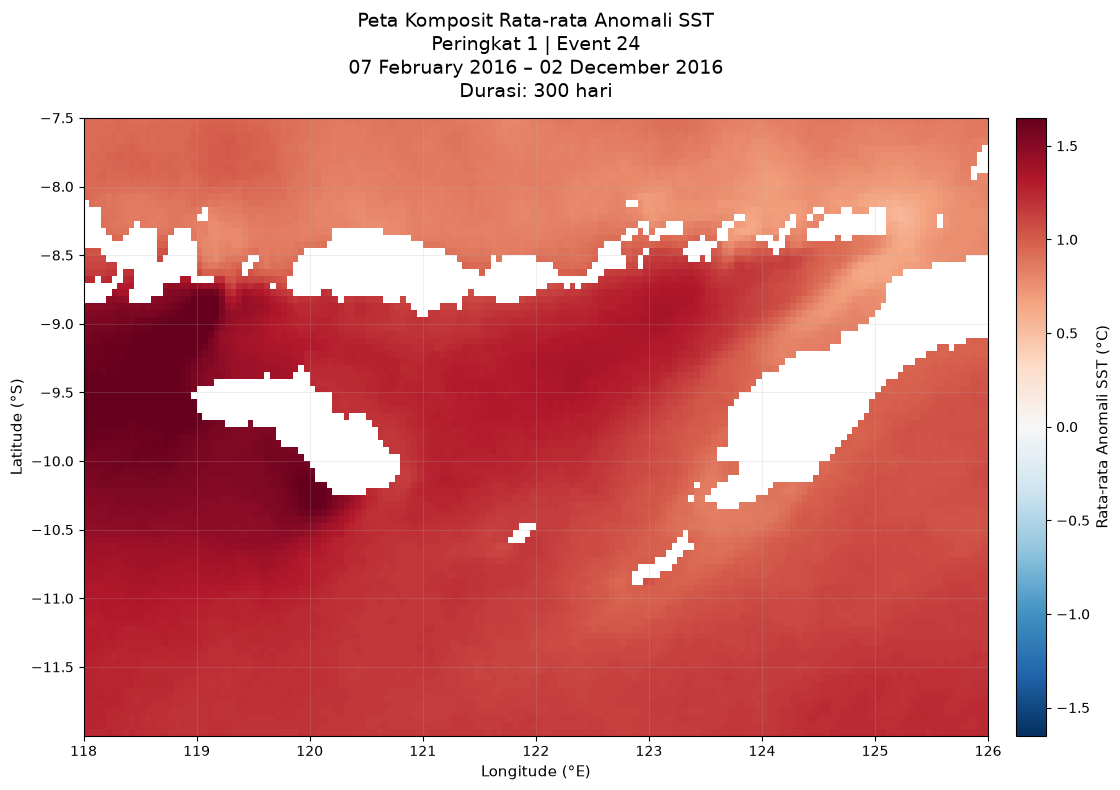

Peta tersimpan: c:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\PETA_KOMPOSIT_ANOMALI_SST_TOP3\Komposit_Anomali_SST_Rank_01_Event_24.png


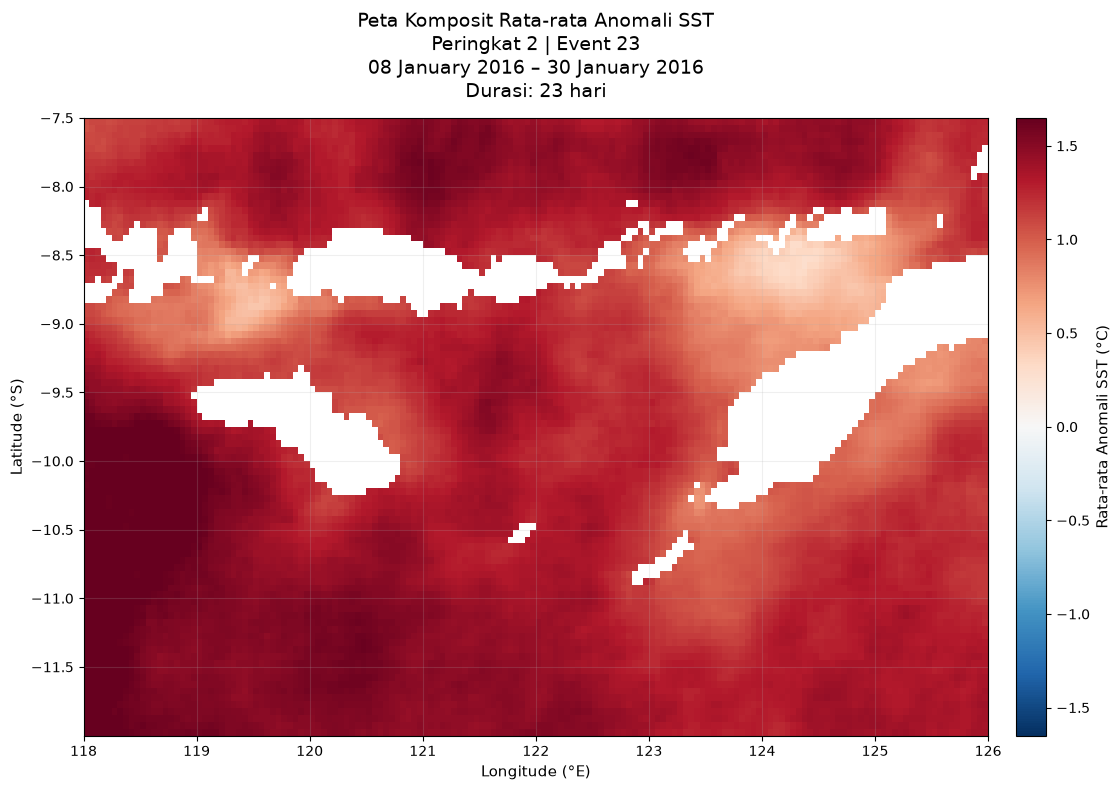

Peta tersimpan: c:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\PETA_KOMPOSIT_ANOMALI_SST_TOP3\Komposit_Anomali_SST_Rank_02_Event_23.png


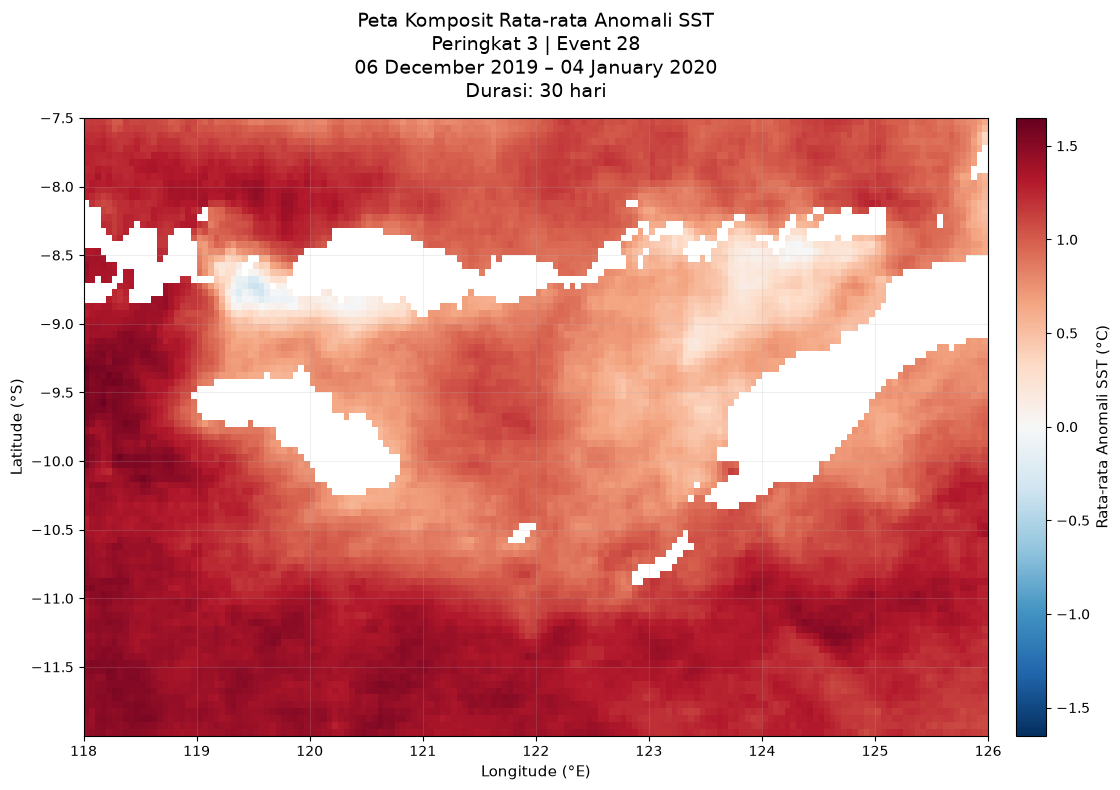

Peta tersimpan: c:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\PETA_KOMPOSIT_ANOMALI_SST_TOP3\Komposit_Anomali_SST_Rank_03_Event_28.png

PEMETAAN KOMPOSIT ANOMALI SST SELESAI
Jumlah peta: 3
Jumlah data grid: 38076
Folder output: c:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\PETA_KOMPOSIT_ANOMALI_SST_TOP3
CSV komposit: c:\Users\WELCOME\Downloads\MENGOLDAT KLIMTROP\PETA_KOMPOSIT_ANOMALI_SST_TOP3\Data_Komposit_Anomali_SST_Top3.csv


,peringkat,event_id,tanggal_mulai,tanggal_akhir,durasi_hari
0,1,24,2016-02-07,2016-12-02,300
1,2,23,2016-01-08,2016-01-30,23
2,3,28,2019-12-06,2020-01-04,30


,peringkat,event_id,tanggal_mulai,tanggal_akhir,latitude,longitude,rata_rata_anomali_SST_C
0,1,24,2016-02-07,2016-12-02,-11.974993,118.025002,1.262483
1,1,24,2016-02-07,2016-12-02,-11.974993,118.075005,1.248983
2,1,24,2016-02-07,2016-12-02,-11.974993,118.125008,1.246717
3,1,24,2016-02-07,2016-12-02,-11.974993,118.175003,1.247956
4,1,24,2016-02-07,2016-12-02,-11.974993,118.225006,1.249897


In [24]:

# ============================================================
# PETA KOMPOSIT RATA-RATA ANOMALI SST
# BERDASARKAN 3 KEJADIAN MHW REGIONAL TERPILIH
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ============================================================
# 1. DAFTAR 3 KEJADIAN MHW TERPILIH
#    Mengikuti hasil verifikasi akhir
# ============================================================

top3_events = pd.DataFrame({
    "peringkat": [1, 2, 3],
    "event_id": [24, 23, 28],
    "tanggal_mulai": [
        "2016-02-07",
        "2016-01-08",
        "2019-12-06"
    ],
    "tanggal_akhir": [
        "2016-12-02",
        "2016-01-30",
        "2020-01-04"
    ],
    "durasi_hari": [300, 23, 30]
})

top3_events["tanggal_mulai"] = pd.to_datetime(
    top3_events["tanggal_mulai"]
)

top3_events["tanggal_akhir"] = pd.to_datetime(
    top3_events["tanggal_akhir"]
)


# ============================================================
# 2. PENGATURAN PERHITUNGAN
# ============================================================

# False = rata-rata anomali seluruh grid laut valid
# True  = rata-rata anomali hanya pada hari/grid yang mengalami MHW

ONLY_MHW_DAYS = False

# Folder penyimpanan
output_map = os.path.join(
    os.getcwd(),
    "PETA_KOMPOSIT_ANOMALI_SST_TOP3"
)

os.makedirs(output_map, exist_ok=True)

os.makedirs(output_map, exist_ok=True)


# ============================================================
# 3. PERSIAPAN TANGGAL
# ============================================================

dates_pd = pd.DatetimeIndex(pd.to_datetime(dates))

# Memastikan dimensi data sesuai
assert sst_anomaly_all.shape == sst_values.shape

assert sst_anomaly_all.shape[1:] == (
    len(latitudes),
    len(longitudes)
)

# Menampung hasil komposit
composite_results = []


# ============================================================
# 4. MENGHITUNG RATA-RATA ANOMALI SST SETIAP KEJADIAN
# ============================================================

for _, ev in top3_events.iterrows():

    rank = int(ev["peringkat"])
    event_id = int(ev["event_id"])

    start_date = ev["tanggal_mulai"]
    end_date = ev["tanggal_akhir"]

    # Mengambil indeks tanggal kejadian (inklusif)
    time_mask = (
        (dates_pd >= start_date) &
        (dates_pd <= end_date)
    )

    time_indices = np.where(time_mask)[0]

    if len(time_indices) == 0:
        raise ValueError(
            f"Data tidak ditemukan untuk Event {event_id}"
        )

    # Mengambil anomali SST selama periode kejadian
    anomaly_period = sst_anomaly_all[
        time_indices, :, :
    ].copy()

    # Jika hanya ingin menghitung hari/grid yang mengalami MHW
    if ONLY_MHW_DAYS:

        mask_period = mhw_mask_all[
            time_indices, :, :
        ]

        anomaly_period[mask_period == 0] = np.nan

    # Menghitung rata-rata anomali pada setiap grid
    valid_count = np.sum(
        np.isfinite(anomaly_period),
        axis=0
    )

    anomaly_sum = np.nansum(
        anomaly_period,
        axis=0
    )

    mean_anomaly_map = np.divide(
        anomaly_sum,
        valid_count,
        out=np.full(
            anomaly_sum.shape,
            np.nan,
            dtype=np.float32
        ),
        where=valid_count > 0
    )

    composite_results.append({
        "peringkat": rank,
        "event_id": event_id,
        "tanggal_mulai": start_date,
        "tanggal_akhir": end_date,
        "durasi_hari": int(ev["durasi_hari"]),
        "jumlah_hari_data": len(time_indices),
        "anomali": mean_anomaly_map
    })

    print(
        f"Event {event_id} selesai dihitung | "
        f"{start_date.date()} sampai {end_date.date()} | "
        f"{len(time_indices)} hari"
    )


# ============================================================
# 5. MENENTUKAN SKALA WARNA YANG SAMA
# ============================================================

all_anomalies = np.concatenate([
    result["anomali"][np.isfinite(result["anomali"])]
    for result in composite_results
])

if all_anomalies.size == 0:
    raise ValueError("Tidak terdapat nilai anomali SST valid.")

# Skala simetris dengan pusat nol
common_vmax = float(
    np.nanpercentile(np.abs(all_anomalies), 98)
)

if common_vmax <= 0:
    raise ValueError("Rentang anomali SST tidak valid.")

common_vmin = -common_vmax

color_norm = TwoSlopeNorm(
    vmin=common_vmin,
    vcenter=0,
    vmax=common_vmax
)

print("\nSkala warna seluruh peta:")
print(f"Minimum: {common_vmin:.3f} °C")
print(f"Maksimum: {common_vmax:.3f} °C")


# ============================================================
# 6. MEMBUAT DAN MENYIMPAN 3 PETA KOMPOSIT
# ============================================================

for result in composite_results:

    rank = result["peringkat"]
    event_id = result["event_id"]

    start_date = result["tanggal_mulai"]
    end_date = result["tanggal_akhir"]

    mean_anomaly_map = result["anomali"]

    fig, ax = plt.subplots(figsize=(12, 8))

    mesh = ax.pcolormesh(
        longitudes,
        latitudes,
        mean_anomaly_map,
        shading="auto",
        cmap="RdBu_r",
        norm=color_norm
    )

    # Colorbar
    cbar = plt.colorbar(
        mesh,
        ax=ax,
        pad=0.025
    )

    cbar.set_label(
        "Rata-rata Anomali SST (°C)",
        fontsize=11
    )

    # Judul
    ax.set_title(
        f"Peta Komposit Rata-rata Anomali SST\n"
        f"Peringkat {rank} | Event {event_id}\n"
        f"{start_date:%d %B %Y} – {end_date:%d %B %Y}\n"
        f"Durasi: {result['durasi_hari']} hari",
        fontsize=14,
        pad=15
    )

    ax.set_xlabel("Longitude (°E)", fontsize=11)
    ax.set_ylabel("Latitude (°S)", fontsize=11)

    ax.grid(
        alpha=0.2,
        linestyle="-"
    )

    ax.tick_params(labelsize=10)

    plt.tight_layout()

    # Simpan peta
    filename = (
        f"Komposit_Anomali_SST_Rank_{rank:02d}_"
        f"Event_{event_id}.png"
    )

    map_path = os.path.join(
        output_map,
        filename
    )

    plt.savefig(
        map_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Peta tersimpan:", map_path)


# ============================================================
# 7. EKSPOR NILAI KOMPOSIT ANOMALI KE CSV
# ============================================================

csv_rows = []

for result in composite_results:

    anomaly_map = result["anomali"]

    lon_grid, lat_grid = np.meshgrid(
        longitudes,
        latitudes
    )

    temp_df = pd.DataFrame({
        "peringkat": result["peringkat"],
        "event_id": result["event_id"],
        "tanggal_mulai": result["tanggal_mulai"],
        "tanggal_akhir": result["tanggal_akhir"],
        "latitude": lat_grid.ravel(),
        "longitude": lon_grid.ravel(),
        "rata_rata_anomali_SST_C": anomaly_map.ravel()
    })

    temp_df = temp_df.dropna(
        subset=["rata_rata_anomali_SST_C"]
    )

    csv_rows.append(temp_df)

composite_df = pd.concat(
    csv_rows,
    ignore_index=True
)

csv_path = os.path.join(
    output_map,
    "Data_Komposit_Anomali_SST_Top3.csv"
)

composite_df.to_csv(
    csv_path,
    index=False
)


# ============================================================
# 8. RINGKASAN
# ============================================================

print("\n" + "=" * 60)
print("PEMETAAN KOMPOSIT ANOMALI SST SELESAI")
print("=" * 60)

print("Jumlah peta:", len(composite_results))
print("Jumlah data grid:", len(composite_df))
print("Folder output:", output_map)
print("CSV komposit:", csv_path)

display(top3_events)
display(composite_df.head())
